<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/QP-day5/QP_Day5_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> <a href="https://kaggle.com/kernels/welcome?src=https://github.com/imguru-mooc/AI_CAMPUS/blob/main/QP-day5/QP_Day5_lecture.ipynb" target="_blank"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" alt="Open In Kaggle"/></a>

# Quantization·Pruning Day 5 — Pruning: 가지치기와 실제 속도

**온디바이스 AI · Quantization·Pruning 5/6 · 11/20(금)** · Google Colab 또는 Kaggle · **GPU (T4) 권장** · PyTorch · torch-pruning · TensorRT 10

Day 1 ~ 4 는 숫자를 **작게** (32비트 → 8 · 3비트) 했습니다. 오늘은 숫자를 **적게** — 필요 없는 weight · 채널을 잘라 냅니다 (**Pruning, 가지치기**).

1. 크기가 작은 weight 를 0 으로 만드는 **unstructured pruning** 으로 70 ~ 90% 를 지워 보고,
2. 그런데도 **왜 빨라지지 않는지** (크기 · 지연 측정, 2:4 sparsity) 확인한 뒤,
3. 채널을 통째로 빼는 **structured pruning** 을 손으로, 이어서 **torch-pruning** 으로 하고,
4. **fine-tuning** 으로 정확도를 되찾아 **ONNX → TensorRT FP16** 에서 진짜로 빨라지는지 잽니다.
5. 마지막으로 **0 / 20 / 40 / 60%** 가지치기 곡선 (MACs – 정확도 – 지연) 에서 쓸 만한 비율을 고릅니다.

> **0 만들기 (unstructured)** → **왜 안 빨라지나** → **채널 빼기 (structured)** → **의존성 그래프** → **fine-tuning** → **배포 · 측정** → **비율 고르기**

오늘의 목표

1. magnitude 기준과 가지치기 단위 (weight · filter · channel · layer) 를 설명하고 weight 분포에서 임계값을 구할 수 있다.
2. `torch.nn.utils.prune` 으로 layer 별 · global unstructured pruning 을 하고 mask · `prune.remove` 를 설명할 수 있다.
3. 0 이 90% 인 모델이 저장 · 압축 · 지연에서 어떻게 다른지 재고, 2:4 semi-structured sparsity 의 조건을 말할 수 있다.
4. L1-norm 으로 filter 를 골라 conv → BN → conv 사슬을 **직접** 줄이고, residual 이 왜 제약이 되는지 설명할 수 있다.
5. **torch-pruning** 의 DependencyGraph · MetaPruner 로 ResNet-20 을 줄이고 MACs · params 를 셀 수 있다.
6. fine-tuning 회복 곡선과 one-shot vs iterative 를 비교하고, ONNX → TensorRT FP16 에서 unstructured · structured 의 속도를 비교할 수 있다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | Pruning 개념 — 기준 · 단위 · weight 분포 |
| 2 | 10:00–10:50 | Unstructured pruning — mask · layer 별 vs global |
| 3 | 11:00–11:50 | 왜 빨라지지 않나 — 크기 · 지연 · 2:4 sparsity |
| 4 | 13:00–13:50 | Structured pruning 직접 하기 — L1-norm filter 제거 |
| 5 | 14:00–14:50 | torch-pruning — DependencyGraph · MetaPruner · MACs |
| 6 | 15:00–15:50 | Fine-tuning · iterative pruning |
| 7 | 16:00–16:50 | 배포 — ONNX → TensorRT FP16 · 속도 비교 · qp_baseline |
| 8 | 17:00–17:50 | 미니 프로젝트 — 가지치기 비율 곡선 · 채점 |

**노트북 사용법**

1. 아래 **0. 실행 환경 준비**대로 내 사본을 만들고 **GPU (T4)** 런타임으로 바꿉니다. 오늘도 **학습 (fine-tuning)** 이 있습니다 — GPU 에서는 3 epoch 가 십여 초, CPU 에서는 40 ~ 60초씩 걸립니다 (CPU 로도 끝까지 됩니다).
2. **✍️ 직접 구현** 셀은 `# TODO` 를 직접 작성합니다. 확인 셀이 `✅` 를 출력하면 정답입니다. 막히면 **💡 힌트** 셀 (실행할 때마다 하나씩 더).
3. **🔒 정답 보기** 셀은 **실습마다 다른 잠금 코드**로 잠겨 있습니다. 정답을 연 기록은 8교시 채점 셀에 표시됩니다.
4. **▶ 예제 (제공 코드)** 셀은 직접 구현이 아닙니다 — 그대로 실행하고 출력 · 해설을 읽습니다. 뒤 교시가 이 셀의 함수 · 변수를 쓰므로 **건너뛰지 말고 실행**하세요.
5. **학습 결과 · 시간은 GPU · 세션마다 조금씩 다릅니다.** 교안의 숫자는 강사 실측 **예시**입니다.
6. 8교시 미니 프로젝트는 끝에 있습니다 (정답 셀 없음). 채점 셀 결과가 보이는 상태로 제출합니다.
6. 수업이 끝나면 **Day 5 복습 퀴즈**(HTML)를 풀고 제출합니다.

## 0. 실행 환경 준비 — Colab 또는 Kaggle

| 단계 | Google Colab | Kaggle |
|---|---|---|
| 열기 | 맨 위 **Open in Colab** 배지 | 맨 위 **Open in Kaggle** 배지 (또는 *File → Import Notebook* 에서 GitHub 주소 붙여넣기) |
| 내 사본 | *파일 → Drive에 사본 저장* | 열면 내 계정의 노트북으로 만들어짐 · 작업 후 **Save Version** |
| **GPU** | *런타임 → 런타임 유형 변경 → T4 GPU* | 오른쪽 패널 *Session options → Accelerator → **GPU T4 x2*** |
| 인터넷 | 기본으로 켜져 있음 | *Session options → **Internet On*** (처음 한 번 **전화번호 인증**) — torch-pruning · TensorRT 설치에 필요 |
| 생성형 AI | 이 노트북은 **생성형 AI 기능이 숨겨진 상태**로 배포됩니다. **다시 켜지 마세요** — 제출 파일에서 이 설정을 확인합니다. *도구 → 설정 → AI 지원* 의 **AI 기반 인라인 완성 표시** 도 꺼 두세요 | 노트북 안에 AI 자동 완성 없음 |
| 숨김 셀 | 🔒 · 🖼 · 💡 셀은 코드가 접혀 있음 | 코드가 보이지만 그대로 실행하면 됨 |

> 아래 **환경 셀**을 실행하면 `실행 환경`, GPU, `torch-pruning` · `tensorrt` 버전이 출력됩니다. 처음에는 설치에 1~2분 걸립니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/animation.html) |
| 📝 Day 5 복습 퀴즈 (수업이 끝난 뒤, 24문항) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/review_quiz.html](https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/review_quiz.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/QP_Day5.pdf](https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/QP_Day5.pdf) |

**오늘의 데이터 · 모델** — Day 2 ~ 4 의 **ResNet-20** (`resnet20_cifar10.pt`, FP32 0.846), CIFAR-10 **학습용 10,000장** (`cifar_train10k.npz`, Day 4 와 같음 — fine-tuning 용), 평가용 2,000장. 모두 노트북이 자동으로 내려받습니다.

> 커리큘럼 초안의 MobileNetV3 대신 Day 2 ~ 4 와 같은 **ResNet-20** 을 씁니다. 같은 모델이어야 양자화 (Day 2 ~ 4) · 가지치기 (오늘) · 지식 증류 (Day 6) 결과를 `qp_baseline.csv` 한 표에서 비교할 수 있습니다. ResNet-20 은 **residual** 이 있어 structured pruning 의 '의존성' 문제를 보여 주기에도 좋습니다.

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, sys, re, glob, json, copy, time, shutil, urllib.request, warnings, inspect, contextlib, io, importlib.util, subprocess
from collections import Counter

# ── 실행 환경 감지 (Colab · Kaggle · 내 PC) ──
try:
    import google.colab  # noqa: F401
    PLATFORM = "Colab"
except ImportError:
    PLATFORM = "Kaggle" if ("KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.isdir("/kaggle/working")) else "Local"
if PLATFORM == "Kaggle":
    os.chdir("/kaggle/working")

def _online(url="https://raw.githubusercontent.com", timeout=5):
    try:
        urllib.request.urlopen(url, timeout=timeout); return True
    except Exception:
        return False
ONLINE = _online()

import torch, torch.nn as nn, torch.nn.functional as F
GPU_OK = torch.cuda.is_available()

# ── 설치 (없을 때만): onnx · onnxruntime · torch-pruning, GPU 이면 TensorRT 10 ──
_need = [p for p in ["onnx", "onnxruntime"] if importlib.util.find_spec(p) is None]
if importlib.util.find_spec("torch_pruning") is None:
    _need.append("torch-pruning==1.6.0")
if GPU_OK and importlib.util.find_spec("tensorrt") is None:
    _need.append("tensorrt-cu12==10.16.1.11")
if _need:
    print("설치:", _need, "— 처음 한 번 2~3분")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_need], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import onnx, onnxruntime as ort
from onnx import numpy_helper
from IPython.display import display
import torch.nn.utils.prune as prune
import torch_pruning as tp
import gzip
try:
    import tensorrt as trt
    TRT_OK = GPU_OK
except ImportError:
    trt, TRT_OK = None, False

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
DEV = "cuda" if GPU_OK else "cpu"
pd.set_option("display.width", 160)
torch.manual_seed(0); np.random.seed(0)
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/QP-day5"
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day5"
EXPORT_KW = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}
CPU = ["CPUExecutionProvider"]
BACKEND = "TensorRT" if TRT_OK else "ORT CPU"

print(f"실행 환경: {PLATFORM} | 작업 폴더: {os.getcwd()} | 인터넷: {'연결됨' if ONLINE else '끊김'} | GPU: {torch.cuda.get_device_name(0) if GPU_OK else '없음'}")
print(f"PyTorch {torch.__version__} | torch-pruning {tp.__version__} | onnx {onnx.__version__} | onnxruntime {ort.__version__} | TensorRT {trt.__version__ if trt else '없음'}")
if not TRT_OK:
    print("⚠️ GPU / TensorRT 없음 — fine-tuning 은 CPU 로 (3 epoch 에 약 40초씩), 7 · 8교시 엔진 셀은 ONNX Runtime CPU 로 대신 잽니다.")

def fetch(name):
    """data/<name> 이 없으면 강의 자료 서버(GitHub Pages → GitHub 원본 순)에서 내려받는다"""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        for url in [f"{BASE}/data/{name}", f"{RAW}/data/{name}"]:
            try:
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                if os.path.exists(path): os.remove(path)
                print("내려받기 실패:", url, "→", e)
        else:
            raise FileNotFoundError(f"{name} 을 내려받지 못했습니다. 인터넷 연결을 확인하거나 강사에게 받은 파일을 data 폴더에 올리세요.")
    return path

@contextlib.contextmanager
def quiet():
    """도구의 긴 로그를 숨긴다"""
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        yield

def size_kb(path):
    return os.path.getsize(path) / 1024

def make_session(path, threads=1):
    so = ort.SessionOptions(); so.intra_op_num_threads = threads
    return ort.InferenceSession(path, so, providers=CPU)

def bench_fn(fn, n=100, warm=10):
    """OT Day 3 · Day 2 의 bench — fn() 을 warm 번 실행한 뒤 n 번 재서 ms 통계"""
    for _ in range(warm):
        fn()
    t = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); t.append((time.perf_counter() - t0) * 1000)
    t = np.array(t)
    return {"mean": float(t.mean()), "p95": float(np.percentile(t, 95)), "fps": float(1000 / t.mean())}

# ── TensorRT (GPU 일 때만) — OT Day 5 의 TRTInfer 그대로 ──
if TRT_OK:
    LOGGER = trt.Logger(trt.Logger.WARNING)
    RUNTIME = trt.Runtime(LOGGER)

    class TRTInfer:
        def __init__(self, engine_path):
            self.engine = RUNTIME.deserialize_cuda_engine(open(engine_path, "rb").read())
            self.context = self.engine.create_execution_context()
            names = [self.engine.get_tensor_name(i) for i in range(self.engine.num_io_tensors)]
            self.inputs = [n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.INPUT]
            self.outputs = [n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.OUTPUT]
            self.buf = {n: torch.empty(tuple(self.engine.get_tensor_shape(n)), dtype=torch.float32, device="cuda") for n in names}
            for n in names:
                self.context.set_tensor_address(n, self.buf[n].data_ptr())
            self.input_shape = tuple(self.engine.get_tensor_shape(self.inputs[0]))

        def __call__(self, x):
            self.buf[self.inputs[0]].copy_(torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)))
            self.context.execute_async_v3(torch.cuda.current_stream().cuda_stream)
            torch.cuda.synchronize()
            return self.buf[self.outputs[0]].cpu().numpy()

        def __repr__(self):
            return f"TRTInfer(in={self.inputs} {self.input_shape}, out={self.outputs})"

    def build_engine(onnx_path, engine_path, fp16=False, int8=False):      # Day 3 실습 4-2
        builder = trt.Builder(LOGGER)
        network = builder.create_network(0)
        parser = trt.OnnxParser(network, LOGGER)
        if not parser.parse_from_file(onnx_path):
            raise RuntimeError("\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))
        config = builder.create_builder_config()
        config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 1 << 30)
        if fp16:
            config.set_flag(trt.BuilderFlag.FP16)
        if int8:
            config.set_flag(trt.BuilderFlag.INT8)
        blob = builder.build_serialized_network(network, config)
        if blob is None:
            raise RuntimeError("빌드 실패 — 위 로그를 확인하세요")
        with open(engine_path, "wb") as f:
            f.write(blob)
        return engine_path

def build_once(onnx_path, engine_path, fp16=False, int8=False):
    """엔진이 이미 있으면 다시 만들지 않는다 (Day 3)"""
    if not os.path.exists(engine_path):
        t0 = time.time(); build_engine(onnx_path, engine_path, fp16=fp16, int8=int8)
        print(f"빌드 {engine_path} — {time.time() - t0:.0f} 초")
    return engine_path

import hashlib, base64, datetime
_HINT_N = {}
def show_hint(no, blob):
    # 💡 실행할 때마다 힌트를 하나씩 더 보여 준다
    hints = base64.b64decode(blob).decode("utf-8").split("\x1e")
    k = min(_HINT_N.get(no, 0) + 1, len(hints)); _HINT_N[no] = k
    for i in range(k):
        print(f"💡 힌트 {i + 1}/{len(hints)} — {hints[i]}")
    print("(다시 실행하면 다음 힌트)" if k < len(hints) else "(힌트를 모두 봤습니다 — 이제 직접 구현해 보세요)")

def show_answer(no, blob):
    # 🔒 잠금된 정답 보기 — 강사가 알려 준 '실습별' 잠금 코드가 있어야 열린다
    raw = base64.b64decode(blob); tag, body = raw[:8], raw[8:]
    for _ in range(2):
        code = input(f"🔒 실습 {no} 잠금 코드: ").strip().upper()
        ks, i = b"", 0
        while len(ks) < len(body):
            ks += hashlib.sha256(f"{code}|qp-day5|{no}|{i}".encode()).digest(); i += 1
        plain = bytes(a ^ b for a, b in zip(body, ks))
        if hashlib.sha256(plain).digest()[:8] == tag:
            with open(".qp_answer_log", "a") as f:
                f.write(f"{no}\t{datetime.datetime.now():%H:%M}\n")
            print(plain.decode("utf-8")); return
        if not code: break
    print("❌ 잠금 코드가 맞지 않습니다. 강사가 이 실습의 코드를 공개하면 다시 실행하세요.")

In [ ]:
# ▶ 데이터 · 모델 셀 — CIFAR-10 · ResNet-20 · 측정 도구
MEAN = np.array((0.4914, 0.4822, 0.4465), np.float32)
STD = np.array((0.2470, 0.2435, 0.2616), np.float32)
ev, tr = np.load(fetch("cifar_eval.npz")), np.load(fetch("cifar_train10k.npz"))

def preprocess(images):
    x = images.astype(np.float32) / 255.0
    return ((x - MEAN) / STD).transpose(0, 3, 1, 2).copy()

X_ev, y_ev = preprocess(ev["images"]), ev["labels"]
if "images" in tr.files:
    Xtr_u8 = tr["images"]
else:                                              # GitHub 25 MB 제한 때문에 10,000장을 100 × 100 모자이크 PNG (무손실) 로 저장한 형식
    _m = cv2.imdecode(tr["images_png"], cv2.IMREAD_COLOR)[..., ::-1]
    Xtr_u8 = np.ascontiguousarray(_m.reshape(100, 32, 100, 32, 3).transpose(0, 2, 1, 3, 4).reshape(-1, 32, 32, 3))
ytr = tr["labels"]

class BasicBlock(nn.Module):                      # VB Day 2 · QP Day 2 ~ 4 와 같은 구조
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, stride=1, padding=1, bias=False); self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = (nn.Sequential(nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout))
                         if stride != 1 or cin != cout else nn.Identity())

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

class ResNet(nn.Module):
    def __init__(self, n=3, n_cls=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        self.layer1 = nn.Sequential(*[BasicBlock(16, 16) for _ in range(n)])
        self.layer2 = nn.Sequential(BasicBlock(16, 32, 2), *[BasicBlock(32, 32) for _ in range(n - 1)])
        self.layer3 = nn.Sequential(BasicBlock(32, 64, 2), *[BasicBlock(64, 64) for _ in range(n - 1)])
        self.pool = nn.AdaptiveAvgPool2d(1); self.fc = nn.Linear(64, n_cls)

    def forward(self, x):
        x = self.layer3(self.layer2(self.layer1(self.stem(x))))
        return self.fc(self.pool(x).flatten(1))

def load_rn20():
    m = ResNet(); m.load_state_dict(torch.load(fetch("resnet20_cifar10.pt"), map_location="cpu")); return m.eval()

def acc_torch(model, X=X_ev, y=y_ev, bs=500):
    model.eval(); dev = next(model.parameters()).device; preds = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            preds.append(model(torch.from_numpy(X[i:i + bs]).to(dev)).argmax(1).cpu().numpy())
    return float((np.concatenate(preds) == y).mean())

def batches(bs=128, seed=0):
    # 학습용 10,000장을 섞어 좌우 뒤집기 · 4픽셀 이동 증강 후 (x, y) 텐서로 (Day 4 와 같음)
    rng = np.random.default_rng(seed); idx = rng.permutation(len(Xtr_u8))
    for i in range(0, len(idx), bs):
        b = Xtr_u8[idx[i:i + bs]]
        b = np.where(rng.random(len(b))[:, None, None, None] < 0.5, b[:, :, ::-1], b)
        pad = np.pad(b, ((0, 0), (4, 4), (4, 4), (0, 0)), mode="reflect"); dx, dy = rng.integers(0, 9, 2)
        yield torch.from_numpy(preprocess(pad[:, dy:dy + 32, dx:dx + 32])).to(DEV), torch.from_numpy(ytr[idx[i:i + bs]]).to(DEV)

def convs(model):
    # 가지치기 대상 — Conv2d · Linear 의 (이름, 모듈) 목록
    return [(n, m) for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))]

def n_params(model):
    return sum(p.numel() for p in model.parameters())

def latency_torch(model, n=200, warm=20):
    # PyTorch CPU · 배치 1 평균 지연 (ms)
    model = model.cpu().eval(); x = torch.from_numpy(X_ev[:1])
    with torch.no_grad():
        return bench_fn(lambda: model(x), n=n, warm=warm)["mean"]

def export_b1(model, path):
    # 배치 1 고정 ONNX 로 내보내기 (TensorRT 엔진용) — 모델은 CPU 로 옮겨서
    model = model.cpu().eval()
    torch.onnx.export(model, torch.zeros(1, 3, 32, 32), path, input_names=["input"], output_names=["logits"], opset_version=17, **EXPORT_KW)
    return path

def onnx_acc(path, X=X_ev, y=y_ev):
    s = make_session(path, 0)
    return float(np.mean([s.run(None, {"input": X[i:i + 1]})[0].argmax() == y[i] for i in range(len(X))]))

EX_IN = torch.randn(1, 3, 32, 32)               # torch-pruning 이 그래프를 따라갈 때 쓰는 예시 입력
EPOCHS = 3
rn20 = load_rn20()
FP32_ACC = acc_torch(rn20)
print(f"학습용 {Xtr_u8.shape} · 평가용 {X_ev.shape} | 장치 {DEV} | ResNet-20 FP32 정확도 {FP32_ACC:.4f} · params {n_params(rn20):,}")

## 1교시 — Pruning 개념: 무엇을, 어떤 단위로 자르나

학습이 끝난 신경망에는 **거의 0 인 weight** 가 많습니다. 이것을 잘라 내도 출력은 거의 변하지 않습니다 — 이것이 가지치기의 출발점입니다.

| 질문 | 선택지 | 오늘 쓰는 것 |
|---|---|---|
| **무엇을** 자르나 (기준, criterion) | **magnitude** (\|w\| 가 작은 것) · gradient (w × ∂L/∂w, 지우면 손실이 얼마나 변하나) · 학습된 중요도 | magnitude (L1) |
| **어떤 단위로** 자르나 (granularity) | **weight 1개** · N:M 묶음 · **filter (출력 채널)** · 입력 채널 · **layer 전체** | weight · filter |
| **어떻게** 자르나 (schedule) | 한 번에 (one-shot) · 여러 번 나눠서 (iterative) | 둘 다 비교 |
| **자른 뒤** | 그대로 · **fine-tuning** 으로 회복 | fine-tuning |

| 단위 | 이름 | 정확도 영향 | 실제 속도 |
|---|---|---|---|
| weight 1개 | **unstructured** | 가장 작음 (가장 정교) | 일반 커널에서는 **그대로** — 0 도 곱한다 |
| N:M (2:4) | semi-structured | 중간 | 전용 하드웨어 (Ampere+ Sparse Tensor Core) 에서만 |
| filter · channel | **structured** | 큼 → fine-tuning 필요 | 텐서가 **진짜로 작아져** 어디서나 빨라짐 |
| layer · block | depth pruning | 매우 큼 | 빨라짐 |

> 오늘의 결론을 먼저 말하면: **실무에서 속도를 얻는 것은 structured pruning** 입니다. 하지만 '왜' 그런지를 unstructured 부터 재 보면서 확인합니다.

> 🎬 **애니메이션** [D5-1 가지치기 단위와 기준](https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/animation.html#d5-1)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

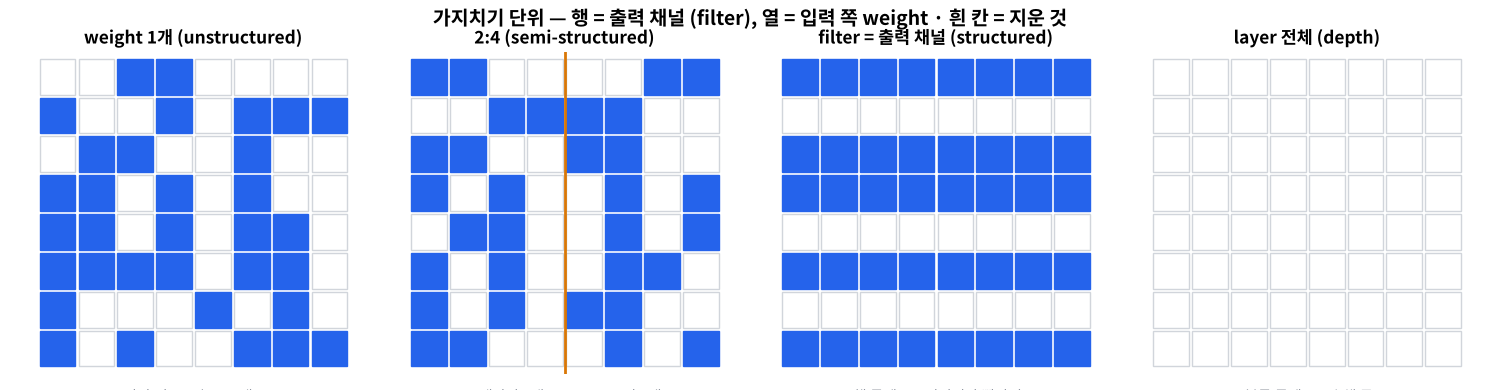

In [ ]:
#@title 🖼 그림 — 가지치기 단위 — weight · filter · channel · layer
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day5/img/f1_units.png", embed=True, width=860))

**▶ 예제 1-A (제공 코드 — 실행만)** 학습된 weight 는 어떻게 분포할까요? ResNet-20 의 **모든 Conv2d weight** 의 절댓값을 1차원으로 이어 붙인 `w_all` 의 로그 스케일 히스토그램을 그리고, |w| 가 0.01 · 0.02 · 0.05 보다 작은 비율을 `small` 에 담습니다. 0 근처에 얼마나 몰려 있는지 보세요.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 1-A — 제공 코드 (그대로 실행)
w_all = torch.cat([m.weight.detach().abs().flatten() for n, m in convs(rn20) if isinstance(m, nn.Conv2d)])
small = {t: float((w_all < t).float().mean()) for t in [0.01, 0.02, 0.05]}

plt.figure(figsize=(7, 2.8))
plt.hist(w_all.numpy(), bins=100, log=True, color="tab:blue")
for t in small:
    plt.axvline(t, ls="--", c="tab:red", lw=1)
plt.xlabel("|w|"); plt.ylabel("count (log)"); plt.title("ResNet-20 conv weight magnitude"); plt.tight_layout(); plt.show()
print(f"conv weight {len(w_all):,}개 |", {k: round(v, 3) for k, v in small.items()})

In [ ]:
assert len(w_all) == sum(m.weight.numel() for m in rn20.modules() if isinstance(m, nn.Conv2d)) and float(w_all.min()) >= 0
assert set(small) == {0.01, 0.02, 0.05} and 0 < small[0.01] < small[0.02] < small[0.05] < 1
print(f"✅ |w| < 0.05 인 weight 가 {small[0.05] * 100:.0f}% — 이것들을 지워도 출력이 크게 변할까요?")

> 💡 **예제 1-A 해설** — 강사 실측: conv weight 270,256개 중 |w| < 0.01 이 21%, < 0.02 가 40%, < 0.05 가 76%. 0 근처에 몰린 종 모양 분포라 '작은 것부터 지우기 (magnitude)' 가 자연스러운 기준이 됩니다. 다만 magnitude 는 '값이 작다' 만 볼 뿐 '중요하지 않다' 를 보장하지는 않습니다 — 그래서 gradient 기반 기준 (w × ∂L/∂w) 도 쓰입니다.

**✍️ 직접 구현 1-1** 텐서 `w` 에서 절댓값이 작은 순서로 `sparsity` 비율만큼을 0 으로 만들 **mask** (남길 곳 1, 지울 곳 0) 를 돌려주는 `magnitude_mask(w, sparsity)` 를 만드세요. k = round(sparsity × 원소 수) 번째로 작은 |w| 를 임계값으로 씁니다 (`kthvalue`). k = 0 이면 모두 1.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 1-1 — 실행할 때마다 하나씩
show_hint("1-1", "ayA9IGBpbnQocm91bmQoc3BhcnNpdHkgKiB3Lm51bWVsKCkpKWAsIGsgPT0gMCDsnbTrqbQgYHRvcmNoLm9uZXNfbGlrZSh3KWAuHuyehOqzhOqwkjogYHcuZGV0YWNoKCkuYWJzKCkuZmxhdHRlbigpLmt0aHZhbHVlKGspLnZhbHVlc2Ag4oCUIGsg67KI7Ke466GcIOyekeydgCB8d3wuHm1hc2s6IGAody5kZXRhY2goKS5hYnMoKSA+IHRocikuZmxvYXQoKWAg4oCUIOyehOqzhOqwkiDsnbTtlZjripQgMC4=")

In [ ]:
# ✍️ 직접 구현 1-1 — magnitude mask
def magnitude_mask(w, sparsity):
    # TODO
    pass

w1 = rn20.layer2[0].conv1.weight
for s in [0.3, 0.5, 0.9]:
    print(f"sparsity {s:.1f}: mask 의 0 비율 {1 - magnitude_mask(w1, s).mean():.3f}")

In [ ]:
_m = magnitude_mask(torch.tensor([0.1, -0.5, 0.3, 0.05, -0.2, 0.4]), 0.5)
assert _m.tolist() == [0, 1, 1, 0, 0, 1], _m
assert magnitude_mask(w1, 0.0).mean() == 1 and abs(float(1 - magnitude_mask(w1, 0.7).mean()) - 0.7) < 0.01
print("✅ magnitude mask — 작은 절반을 지움:", _m.tolist())

In [ ]:
#@title 🔒 정답 보기 1-1 — 강사가 알려 준 실습 1-1 잠금 코드를 입력하세요
show_answer("1-1", (
    "Y05WCu90A6slaqDXOg8Ma2KHAZk+NPngJPTvpGQPmSu4GH/ppDSjm63N0t75wYrucpOObAQviq6SHQyq6DNdJsxX"
    "XEb6USLfQcSozJCzlwN5Lp4ZS9f5J97EYxx7a/E1AfBxbR5a80MpVGhWtXpo+KUpWTo8pB8UnTWw0DU2NdlAQpIo"
    "9SPy59X3ijbdhxINbjFkyjqJ52/SKTYiiqQ2kJ1io1dOquNm5FzBkyRPA9Thnb0/st53jH+Dck+9vP5i8roZuQq4"
    "uFqu0qZJoejb72G2y5Stkj1VFYSznpJGdyIbWsjigky2HuO1b+XGNF10kqHWP9eYpnLqKz/JHS1pvcVIkQG+cIms"
    "dRFEloZBUlyxGupjzJTyh7IsEtgC97bkd1effzj/tR32SN7rNZPdH6oXNFt8hx80VYC2GVokH1RsA/oDbHYzDMW4"
    "6KOb2wYYeOkQGXI1m/ubm28qFgswhBASiLJDoQO0Kf63Fe81FtKOj/k9ZaYCHg4L+mjxWjVICiuPnG43dQ8/oO7H"
    "O5+XTqWvV5xDG937k56+6pHgCs3nmrBK3NkH6FuinWfuBl2MtLIjKgEC74gzJcpY+0Eo8IP73BdtM2VpQ7dqa+oV"
    "xPmfiSJWcbpSq26Is3+if/oYV0o8/lmTtQHLY6FkLxkPOK/bUZJwHqLPCcQGRARDHsfDzgny/UVpiOCMQFa4YKem"
    "FQoOUVEzubrJ3fRZ8RQULqWjGq3xE7493Dr+ueF6cpPFEArG7BLdFNOTfZbSAdstjzCpsBWLiDZfTtWmtILBY3Y7"
    "99/rcgGMqqznC7xpPfh/fAiw01xhbZHWk8GmY96n4xChjj1ynGKYsvsMHnSM/dj+qtxyjDVr8BIIAh4CfLU+LRCc"
    "vP8fu+gc9HPJ39JGLEGbAwapDheXaykLZulnREopsB9+2V/Eqz1/UB1ZPP4hddLx2XCXwocwY2FSweYn1pXAkD33"
    "sCoM14EXrDMpAQv64FFH6pWL5AFPb/1njQg="
))


**✍️ 직접 구현 1-2** (1) Conv 의 **filter (출력 채널) 별 L1-norm** 을 돌려주는 `filter_l1(conv)` 를 만들고 `rn20.layer1[0].conv1` 의 16개 값을 막대 그래프로 그리세요. (2) `rn20.layer2[0].conv1` (32 × 16 × 3 × 3) 에서 **단위별로 하나를 지울 때 사라지는 weight 수** 를 `units_df` (열 `unit, removed`) 로 만드세요 — 행: `weight`, `filter`, `in_channel`, `layer`.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 1-2 — 실행할 때마다 하나씩
show_hint("1-2", "ZmlsdGVyID0g7Lac66ClIOyxhOuEkCAoZGltIDApIOKGkiDrgpjrqLjsp4Ag7LaVICgxLCAyLCAzKSDsnLzroZwgYGFicygpLnN1bShkaW09KDEsIDIsIDMpKWAuHncyID0gYHJuMjAubGF5ZXIyWzBdLmNvbnYxLndlaWdodGAgKDMyLCAxNiwgMywgMyk6IGZpbHRlciDtlZjrgpggPSBgdzJbMF0ubnVtZWwoKWAsIOyeheugpSDssYTrhJAg7ZWY64KYID0gYHcyWzosIDBdLm51bWVsKClgLCBsYXllciA9IGB3Mi5udW1lbCgpYC4=")

In [ ]:
# ✍️ 직접 구현 1-2 — filter L1-norm · 단위별 크기
def filter_l1(conv):
    # TODO
    pass

n1 = filter_l1(rn20.layer1[0].conv1)
# TODO: 막대 그래프

w2 = rn20.layer2[0].conv1.weight
units_df = None   # TODO: 열 unit, removed — 행 weight, filter, in_channel, layer
display(units_df)

In [ ]:
assert torch.allclose(filter_l1(rn20.layer1[0].conv1), rn20.layer1[0].conv1.weight.abs().sum((1, 2, 3)))
assert units_df.removed.tolist() == [1, 144, 288, 4608] and units_df.unit.tolist() == ["weight", "filter", "in_channel", "layer"]
print(f"✅ filter 하나 = weight 144개 — 가장 작은 filter L1 {float(n1.min()):.2f} vs 가장 큰 {float(n1.max()):.2f}")

In [ ]:
#@title 🔒 정답 보기 1-2 — 강사가 알려 준 실습 1-2 잠금 코드를 입력하세요
show_answer("1-2", (
    "GrPRONSkv8otnMQtjv2Mc1wZt1s/PAK+PhOew9E+aZt6c9JXUv2fAv0Bfrwz9adOkDpg/8KwQbhJFNyUSugnQjOh"
    "J1A6TFoztai9kGbsgeFcVqsUogFAoJygdlh2QSGtf4Wp9e45NUzkYcTLbg5HpeD26WkLH6rXw4F2nLWXi2bnb5EV"
    "qt0/npkvH3aS/tSuR2u4BbIhFOF7a5YC9ttqw1so4rBNS1oAiB4o097S718pVHJvHlCaI7ES03mxJE94E08snZEu"
    "zuLdL8U+6EiHKUSTWWCI3+CTUgKeDCfHal49hVmlvVoEBYuNZM1p4kdwOvkjyBq7lNHyylKhvaRS3jdeJxxAZ5bN"
    "EqnCTtrS93QJWuCjKcVisVqCSCFP/qHoy+uCQcvttChwnRa03ZC9OrBoP6ha8DdYzskbKET1owBThFTMGAkjDo1c"
    "drxK4QEQRXKgQIPrdgKNJXoGm8pImAd8dt6kCQguABGhmkbXggK+ffTJzEEg/xhcndu0rADtB2uM5DzJBbqwZsIE"
    "hjLHkTa3RVXVbjoUO5l5+TiCCwJfoKAZwLtuTmbczIjDsSAnJKJwWXk4E5653GmrOnS256qJzrpggU5j66HBfo5L"
    "AElTeUqZQ1oz9S67ragGrkZc4tgITyQtYZJmGss4vorAX6iOfW8PtHLKpiMAmjKuDr6dGyGDLwVmrlWDq8dNuF1g"
    "bkf8t+v5YyM+045ETbWMrPpR8pLIe+FCQlexgVPNyhA64Nz+RLO2EXDmMPi5vPDM19U47D0wqWmbPpA79TtuapzU"
    "ay0eIGQdHtTvO+rUfSeMk886eVMrEDO4drlZYZ4eV327AdVGBLGcI6c3bmNRGKYn679cAwc58waUiaztEcGqOPVW"
    "pXtBwKPOj4aXrBLoRVLV1MW133iVURimGsi/XAmS2BbXuIGTqflRSNSQjIgmexdKgZcwRTvCwpq4st+eNNhiCeml"
    "Up2Dir49oeLalTdezEJLCl/WoLq/GFYzPXb/ZqqVRokzSAGj6SbEwe/1ou8JViVSzN21bND4ZcGKoQ1rJtKUHA11"
    "QrpGvxUQeE7Evbxg3iYbptp+XhtmpEmuLMMVGZqpPK0CglfKmlEsoO1wqFrEO/jqu98g57MioYvRFQW9HyQ2dWIJ"
    "+c3T+TjGrHcT0WkvcV65Vrd55g+vwOa11r4k9cyMJ5hm/TON2/5Ik3O9fEIfe6kE8UFFrskFTeVg5uuGKIqJ4gm7"
    "tsDIhmEnE7aLLDQ5GDmWR/IBd2n1Sgg5hEq6VniB808Vx6XBupjYUNuHRN4pOCPvDJAvj0WPgkQlepe3kdKXity3"
    "EDued/QF3XAD7iUx7nmid43POARDk2xTD4xjxNsrp5M3Q+/G+XLUyqtG5XqtfUanRKqrXJX/vkKN2Z2gaGNEAu8U"
    "vvVLO+g3zC4Jg073uDcp3AwFxkkuqKlIbit9xTg8tnusxn4PS6ml9NNSlbY+QqGOpeznHBN37Q=="
))


#### 📌 1교시 정리

- 가지치기 = **기준** (magnitude · gradient) × **단위** (weight · N:M · filter · layer) × **방식** (one-shot · iterative) × **회복** (fine-tuning).
- 학습된 weight 는 0 근처에 몰려 있다 → magnitude 기준의 근거. mask 는 weight 와 같은 모양의 0/1 텐서.
- 단위가 클수록 정확도 손해는 크지만, 실제 속도 이득은 커진다.

## 2교시 — Unstructured pruning: mask · layer 별 vs global

`torch.nn.utils.prune` 은 weight 를 직접 지우지 않고 **mask 를 곱하는 방식**으로 가지치기합니다.

| 함수 | 하는 일 |
|---|---|
| `prune.l1_unstructured(module, "weight", amount=0.5)` | 그 층 안에서 \|w\| 가 작은 50% 를 mask 0 |
| `prune.global_unstructured([(m1, "weight"), ...], pruning_method=prune.L1Unstructured, amount=0.5)` | **모든 층을 한데 모아** 작은 50% — 층마다 비율이 달라짐 |
| `prune.remove(module, "weight")` | mask 를 weight 에 **영구 반영**하고 mask · weight_orig 를 없앰 |

가지치기 직후 모듈 안은 이렇게 바뀝니다.

```
weight (Parameter)   →   weight_orig (Parameter, 원래 값)  +  weight_mask (buffer, 0/1)
                         weight = weight_orig * weight_mask  (forward 전에 매번 계산 — hook)
```

> **layer 별 vs global** — 층마다 똑같이 50% 를 지우면 weight 가 적고 중요한 층 (stem · 마지막 fc) 도 50% 를 잃습니다. global 은 '전체에서 작은 것' 을 지우므로 중요한 층은 덜, 큰 층은 더 지웁니다.

> 🎬 **애니메이션** [D5-2 mask 와 global](https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/animation.html#d5-2)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

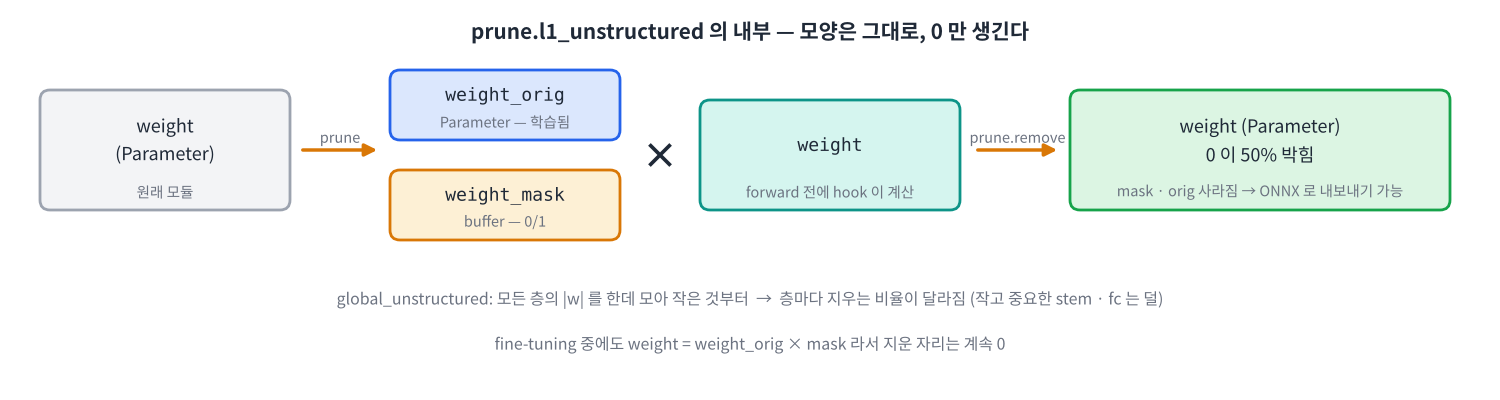

In [ ]:
#@title 🖼 그림 — prune 의 내부 — weight_orig × weight_mask, 그리고 prune.remove
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day5/img/f2_mask.png", embed=True, width=860))

**✍️ 직접 구현 2-1** `rn20` 의 복사본에서 `layer1[0].conv1` 하나에만 `prune.l1_unstructured(amount=0.5)` 를 적용하세요. 적용 직후의 **parameter 이름** `params_before`, **buffer 이름** `buffers`, 0 비율 `sp_masked` 를 구하고, `prune.remove` 뒤의 parameter 이름 `params_after` 를 구하세요 (이름은 정렬한 리스트).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 2-1 — 실행할 때마다 하나씩
show_hint("2-1", "YHBydW5lLmwxX3Vuc3RydWN0dXJlZChjb252LCAid2VpZ2h0IiwgYW1vdW50PTAuNSlgLh7snbTrpoQ6IGBzb3J0ZWQobiBmb3IgbiwgXyBpbiBjb252Lm5hbWVkX3BhcmFtZXRlcnMoKSlgLCBidWZmZXIg64qUIGBuYW1lZF9idWZmZXJzKClgLh4wIOu5hOycqCBgZmxvYXQoKGNvbnYud2VpZ2h0ID09IDApLmZsb2F0KCkubWVhbigpKWAg4oaSIOq3uOuLpOydjCBgcHJ1bmUucmVtb3ZlKGNvbnYsICJ3ZWlnaHQiKWAu")

In [ ]:
# ✍️ 직접 구현 2-1 — prune 의 내부 들여다보기
m = copy.deepcopy(rn20); conv = m.layer1[0].conv1
# TODO: l1_unstructured 50%
params_before, buffers, sp_masked = None, None, None   # TODO
# TODO: prune.remove
params_after = None   # TODO
print("적용 직후 parameters:", params_before, "| buffers:", buffers, f"| 0 비율 {sp_masked:.3f}")
print("prune.remove 뒤 parameters:", params_after, f"| 0 비율 {(conv.weight == 0).float().mean():.3f}")

In [ ]:
assert params_before == ["weight_orig"] and buffers == ["weight_mask"] and params_after == ["weight"]
assert abs(sp_masked - 0.5) < 0.01 and abs(float((conv.weight == 0).float().mean()) - 0.5) < 0.01
print("✅ weight_orig × weight_mask → remove 하면 다시 weight 하나 (0 은 그대로 남음)")

In [ ]:
#@title 🔒 정답 보기 2-1 — 강사가 알려 준 실습 2-1 잠금 코드를 입력하세요
show_answer("2-1", (
    "UTIEDUUcuWNyG+4mU5HzOwWFJemz9FxhuWJ9BSS/ngteFmH2XZ9kDeLeoA3fSc909ZKHi4y15pI60IGi544rYBzs"
    "H6ySMsGOv3MzSABaJBoZAK8gAB0mjyjCON8gMly8hknDlnBgs6T2Jad3f5mfsOpAjyHmzjLdyywB98M5oZSOZZ+4"
    "gW3frYc3DS5bdDhtzVVc0i9P0EZlGhRbP7ZDyWszOG75SY77rvmwl2vhAjkCyeqOFioBHZGRCh17FJfI0l+A8zj7"
    "tH8Kx5Ae5HSxnHO+Q5B0+UViXzMIvA5TeWXIZvBbMqGBcaMxL1cDNa7pBuygFjSMG4hpy7nFZUOnX6up8CwUbhyE"
    "D6nPvteDNivuYUpu+JuWuNQDfP+2sW6Dn0N35ocQW6SHDgvyyQ+cUwK1Xv1lioljgRAwOfyJOTY+58soesVVIE0p"
    "Wd+Lm3U9oUrbefhDTau/RiNLA6iZWHGe0MJ9NH/M+LXZ6eSZOQkIzl/RlXm9AoWc0vJzkxltqH/ZUiZ2SycFJujp"
    "c32oJwufKY8YNtTjyLzv/mxxlIgAvh0W4mK+/l9BwRA4CjJLV/7cUNbUPLqfOSpM0cBTXOCjZDhc+RR/Nh312Zxy"
    "/OZ5bhTyCPZMSvhEyLuPPHuAGRej0HUJKkFvhbvmebDHvo5CszYD0TDIV5fUkxdUBBPcOICROfiRgIREinVWs97O"
    "c9eooEvnTG478I0hZdf3IrASTbStXC1rVWrTEwEu3anvmWE2R8uUADtfdWiYtEonPHmvMAmTj1TjIPFEh0I0KdmV"
    "RBNzYwSVMJj58oCkk3wG6xYCsSheLkPcmwnV+nOUZ+crcxy8aHOu9jVBO+vBoApT7urbxxGwStUrc9ja2Za8C4/i"
    "71Jtuc0u7q/PXr//n6H7+lSCl9yck8Ow8oaLpZ5YeG/I8/PjfYBaPqIgRgCHJrO7e9bUyDpPwjn+8SogocRwUj5k"
    "5X29pB8LzD3lYW6vdzbZipnkvtYv4wW7zbvn0AzraUaj4d8BafkYf+3mvcOijqKZMSUT2l3eKu3i4mbqwJqAf3rf"
    "PYtk6gv/vmp0rVOOCQi4w0twIuJbveLECzDRniHpAQLhDFuF4qC8RGUAzKzAhbvQ3F+Oqwofxa0Msed2LiGQiTov"
    "GWw1X/oj9kLzYNFv9hAb7B2xqZAKkGl62/MMtN4eD2R+TkJtuOd8pQD6HNURrp5RWztKtNvhmMTZ7L8+9DXmSYV7"
    "Wi0dXlY+wpdUztppnzVIfulDpcxQ9E3wDrnYeD/4yvpVrFK1DqNFMNO81mBXzCwlXPfrOOsDAZHpBxbwevsmFtWb"
    "uVKFGY28YNfp4US9ixq5NNzq9YittaBvkhYGyiL/sGEMLNPRpA8rcVHUy7BXumVlbG0="
))


**✍️ 직접 구현 2-2** (1) 모델의 `convs()` 전체 weight 중 0 의 비율을 돌려주는 `sparsity(model)` 을 만드세요. (2) 모델을 **복사**해서 `scope="global"` 이면 `global_unstructured`, `"layer"` 면 층마다 `l1_unstructured` 로 `amount` 만큼 지우고 **`prune.remove` 까지 한** 모델을 돌려주는 `prune_unstructured(model, amount, scope="global")` 을 만드세요 (대상: `convs()` 전체 — fc 포함).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 2-2 — 실행할 때마다 하나씩
show_hint("2-2", "c3BhcnNpdHk6IDAg7J2YIOqwnOyImCDtlakgLyDsm5Dshowg7IiYIO2VqSDigJQgYCh3ID09IDApLnN1bSgpLml0ZW0oKWAsIGB3Lm51bWVsKClgLh50YXJnZXRzID0gYFsobW9kLCAid2VpZ2h0IikgZm9yIG4sIG1vZCBpbiBjb252cyhtKV1gIOKAlCBtIOydgCBgY29weS5kZWVwY29weShtb2RlbClgLh5nbG9iYWw6IGBwcnVuZS5nbG9iYWxfdW5zdHJ1Y3R1cmVkKHRhcmdldHMsIHBydW5pbmdfbWV0aG9kPXBydW5lLkwxVW5zdHJ1Y3R1cmVkLCBhbW91bnQ9YW1vdW50KWAsIGxheWVyOiDqsIHqsIEgYHBydW5lLmwxX3Vuc3RydWN0dXJlZChtb2QsIG5hbWUsIGFtb3VudD1hbW91bnQpYC4e66eI7KeA66eJ7JeQIOuqqOuToCB0YXJnZXQg7JeQIGBwcnVuZS5yZW1vdmUobW9kLCBuYW1lKWAu")

In [ ]:
# ✍️ 직접 구현 2-2 — sparsity · prune_unstructured
def sparsity(model):
    # TODO
    pass

def prune_unstructured(model, amount, scope="global"):
    # TODO
    pass

g50, l50 = prune_unstructured(rn20, 0.5, "global"), prune_unstructured(rn20, 0.5, "layer")
print(f"global 50%: sparsity {sparsity(g50):.3f} · 정확도 {acc_torch(g50):.4f} | layer 50%: sparsity {sparsity(l50):.3f} · 정확도 {acc_torch(l50):.4f}")
per_layer = pd.DataFrame([{"layer": n, "global_sp": float((m.weight == 0).float().mean())} for n, m in convs(g50)])
print("global 50% 에서 층별 sparsity — 가장 적게:", per_layer.nsmallest(3, "global_sp").round(3).values.tolist())

In [ ]:
assert sparsity(rn20) < 0.001 and abs(sparsity(g50) - 0.5) < 0.005 and abs(sparsity(l50) - 0.5) < 0.005
assert not hasattr(g50.layer1[0].conv1, "weight_mask") and sparsity(rn20) < 0.001
assert per_layer.global_sp.std() > 0.05
print(f"✅ 같은 50% — global 은 층마다 {per_layer.global_sp.min():.2f} ~ {per_layer.global_sp.max():.2f} 로 다르게 지운다")

In [ ]:
#@title 🔒 정답 보기 2-2 — 강사가 알려 준 실습 2-2 잠금 코드를 입력하세요
show_answer("2-2", (
    "WMEfEfV+X2AQLmIeRyFvD0hFjwPGYnzcsDFiZ77Qa6yfb0TjdOzutJVhzBNZ3mWHlKu8qKzTm4Nqs+ZDlCE32rHS"
    "2mPCqJc04pmZpkynElVutetkDjgFJVqjJyF1XXW/CKXi4+GVIVKEST47uxUyB0dSkYh2rtPoHiymLjm7xSM+7Ah1"
    "JLqSbBdRom6+WNL7WkaxcxqUN8CoVphHcUkZ5KB1HhTwRiRCnR4ZmHaAkpODaWr65pXJ/HY5LqkS/111x2cLIqrv"
    "uSGcyvhkpQeIjlPohoRGh2HzPJimZ7KDjQH4WFwiB6YqXHJ3N8+/XD7THckLwxhygEd7vJB0GR0nxU9AjSNfRH8n"
    "iPxznVkEwbydZft6mEagRyU4ieCsAwpGkUja8tIHd+4khpMs+8hAOF7KqK6wpelx3XnT39Xm7ixlz+/6YZosYlsK"
    "SydoiqZ/6J/KHlnHaHTrjyQuGoa+xZrptkB3F9S6y8uMoy/N4TEAWiCB4eQGAbyVLrOdRbbbxohzShtKBF6xafb2"
    "+PgwxPUERpB/EXOMmIFYDdE1btotgNqfn9wuO2YE91XeQnyRRS8UEsAaLVHureExWf4hHFeuWXYDYoaobYg0XKLn"
    "u9LuQIH4gD9UN8hqrhD1SfxssSe/QPTxkQYkcYub415ycQBne2oDlFGACx8dPFr+XWXz4C56Sn+wdQ1IW4Zu1EEM"
    "c951eQxf0fq2K46P8mEJ+Aj9qKX+nWqO8mihEWP4F5B842YGFRTmUvh+JhOL8Z4MjVJw6VIZgws9p2bhKVcQu9Cz"
    "XkWxa9GgTU7KH10NPnV/UoRFU9hT8mqLPGYZ00mnV3J3xARgwmPDYaiv6W1/ByoyO2NlLZSO69f4CSXfIylbkR5p"
    "5JPufWW+l7kooV+oyAXVLPxU7lscixL2c0Q+xiDO7Y2ChdXfep2jGE40txCjNtgE4rS0MabvquIenp091RNJD7f3"
    "89ZrXckyKxWcUyuW4e/p5VodNTBX/aW7xk/jaVR1pO+aV/lXwUHbP533pFWefcs/NFlw/hxXqo+h7iPEgbqLfiWP"
    "O4xQCkFBtvBl8IXWmBI7fHZviYoqJlA9AltaZQJ0fGgBp2TLOrlmhvdBe9uciY1KR3P2mGHtaKmV+xJhBaS0C7fr"
    "YEErCtYfS0nCSru3gK/zkjwJXsN8FiMZNI//0r06fAMbnKUnKyx9VxJDn0CRxGGNZy1dqp24j3NX8GFlCaVIPYyG"
    "ScIA2qjnIp1b2BS/sqiXR7/DstqhFrIxB2n7GRxcp6sbaH/vlInWazDqqE9H6hIY7nonIG1r3wcGDfDuuGUmwgj7"
    "sX4NuuH0VAFUCrk9xAzRdOqualzciodEbVG5ZVZTbE6gJEnJrhyWC+iuK8N3zwJA3lExKfDCHiWr76OdpL4R9iqT"
    "rJg+GK3kV45MNYlLm+ckJ3z6KeGIRkx2n3Eb1HCit0ckKAVqpACl2AI1ynpmvX78/LOcBSgdHgWoi1O3LaeqgBBV"
    "oa7ctgXGTbitfOGWqa/3BP7utWG4bsdVeVHhww1JjVFsUeduk4lapoEKguFMbAMwsYxxTIAu1N8OA7wVy6mUJSFt"
    "mWxEaZBjrdzfil5LnLeuAZamx0NATJIg4J6XMYjx+XDe20lTZL3bSYTX6wJ5RDRB0M6EakHI6bfPSuXrkWqdTF6Z"
    "SfhIcM9lp3WUH+uJZgK07cDKJ5vVWxrWq+0XgQUf7lgCr8IyZhQhxCy213ewj1T3m89FwT0y97xitJOATp68HjkU"
    "IMuZn8HFzewq7i919P4YtdCmjuYDcVCMUdubx7j3ZTerPsavKYM1dQRIcN2DoAcusXi3FhoAuiOAp1Op79IZYkVY"
    "+st/Diec7zt/ZZJ9JOl9VkFGvDR+u7D/6S/dx6AgU5L7ycAGwBYMMV+AoGFefz+pane7VNoPtB1+vSNEGVWz/9rO"
    "lDMgMIwZTaBX"
))


**▶ 예제 2-A (제공 코드 — 실행만)** sparsity `[0.0, 0.3, 0.5, 0.7, 0.9]` 각각에 2-2 의 `prune_unstructured` 를 global · layer 별로 적용해 정확도를 `us_df` (열 `sparsity, global, layer`) 에 모으고 두 선을 그립니다. **fine-tuning 은 하지 않습니다.** 실행하기 전에, 몇 % 부터 무너질지 먼저 예측해 보세요.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 2-A — 제공 코드 (그대로 실행)
rows = []
for s in [0.0, 0.3, 0.5, 0.7, 0.9]:
    rows.append({"sparsity": s, "global": acc_torch(prune_unstructured(rn20, s, "global")), "layer": acc_torch(prune_unstructured(rn20, s, "layer"))})
us_df = pd.DataFrame(rows)
display(us_df.round(4))
plt.figure(figsize=(5.5, 3))
plt.plot(us_df.sparsity, us_df["global"], "o-", label="global"); plt.plot(us_df.sparsity, us_df["layer"], "s--", label="layer-wise")
plt.axhline(0.1, c="gray", ls=":", label="random (0.1)")
plt.xlabel("sparsity"); plt.ylabel("accuracy"); plt.title("Unstructured pruning (no fine-tuning)"); plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
assert us_df.sparsity.tolist() == [0.0, 0.3, 0.5, 0.7, 0.9] and abs(us_df["global"][0] - FP32_ACC) < 1e-9
assert us_df["global"][1] > FP32_ACC - 0.02 and us_df["global"][2] >= us_df["layer"][2] and us_df["global"][4] < 0.3
print(f"✅ 30% 는 거의 공짜 ({us_df['global'][1]:.3f}), 70% 부터 무너짐 ({us_df['global'][3]:.3f}) — global 이 layer 별보다 버팀")

> 💡 **예제 2-A 해설** — 강사 실측 (global / layer 별): 30% 0.8415 / 0.838, 50% 0.8125 / 0.789, 70% 0.482 / 0.295, 90% 0.10 / 0.10. 작은 ResNet-20 (27만 params) 은 여유가 적어 70% 부터 무너집니다. 큰 모델 (ResNet-50 · BERT) 은 fine-tuning 과 함께 80 ~ 90% 까지 버티기도 합니다.

#### 📌 2교시 정리

- `prune.*` 은 weight 를 `weight_orig × weight_mask` 로 바꾸고, `prune.remove` 로 영구 반영한다 — **모양은 그대로, 0 만 생긴다.**
- global 은 전체에서 작은 것을 지워 층마다 비율이 달라지고, 같은 sparsity 에서 layer 별보다 정확도가 높다.
- ResNet-20 은 fine-tuning 없이 30 ~ 50% 까지 버틴다.

## 3교시 — 왜 빨라지지 않나: 크기 · 지연 · 2:4 sparsity

90% 를 지운 모델은 정말 10배 작고 10배 빠를까요? 재 보면 **둘 다 아닙니다.**

| 무엇 | 0 이 90% 인 모델 | 이유 |
|---|---|---|
| 저장 크기 (`.pt` · `.onnx`) | **그대로** | 0 도 FP32 4바이트로 저장된다 (dense 텐서) |
| 압축 크기 (zip · gzip) | **크게 줄어듦** | 0 이 반복되니 압축이 잘 됨 — 배포 · 다운로드 크기 이득 |
| 지연 (일반 커널) | **그대로** | cuDNN · MKL 의 Conv 는 0 도 곱한다. 0 을 건너뛰는 sparse 커널은 sparsity 가 아주 높아야 이득 |

**예외: 2:4 semi-structured sparsity** — 연속한 weight **4개마다 정확히 2개가 0** 이면, NVIDIA **Ampere 이후 (A100 · RTX 30 · Jetson Orin)** 의 Sparse Tensor Core 가 절반만 계산해 최대 약 2배 빨라집니다 (TensorRT `SPARSE_WEIGHTS` 플래그). **T4 (Turing) 는 지원하지 않습니다.**

```
weight 8개:  [0.3 -0.1  0.05 0.6 | -0.4 0.02 0.2 -0.01]
2:4 mask:    [ 1    0    0    1  |   1   0    1    0  ]    ← 4개마다 큰 2개만
```

> 🎬 **애니메이션** [D5-3 0 은 왜 빨라지지 않나](https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/animation.html#d5-3)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

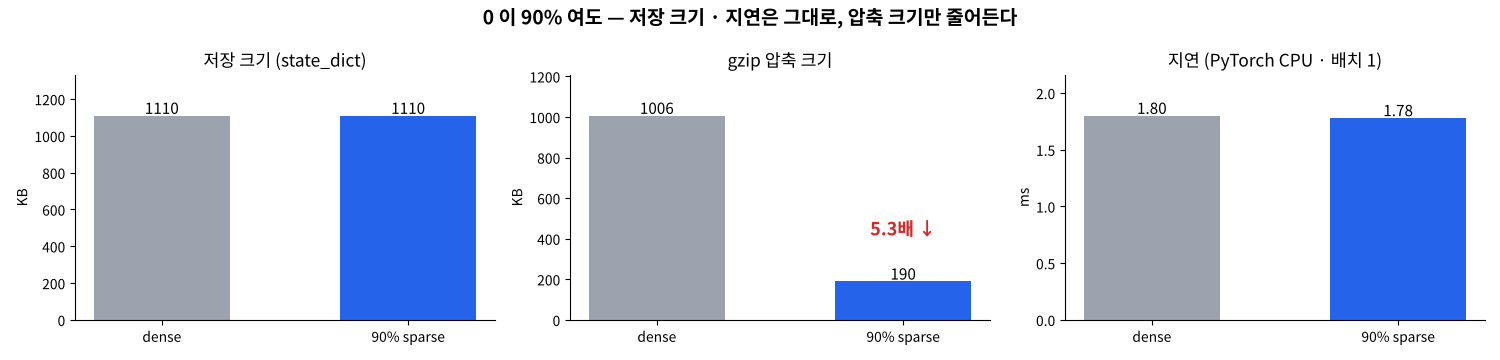

In [ ]:
#@title 🖼 그림 — 0 이 90% 여도 — 저장 크기 · 지연은 그대로, 압축 크기만 줄어든다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day5/img/f3_sparse.png", embed=True, width=860))

**✍️ 직접 구현 3-1** 모델의 state_dict 를 메모리 (`io.BytesIO`) 에 `torch.save` 해서 **원래 크기 · gzip 압축 크기** (KB) 를 돌려주는 `state_kb(model)` 을 만드세요. FP32 원본과 global 90% 모델 `m90` 의 크기를 `size_df` (열 `model, raw_kb, gzip_kb`) 로 비교하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 3-1 — 실행할 때마다 하나씩
show_hint("3-1", "YGJ1ZiA9IGlvLkJ5dGVzSU8oKTsgdG9yY2guc2F2ZShtb2RlbC5zdGF0ZV9kaWN0KCksIGJ1Zik7IHJhdyA9IGJ1Zi5nZXR2YWx1ZSgpYC4eS0I6IGBsZW4ocmF3KSAvIDEwMjRgLCDslZXstpU6IGBsZW4oZ3ppcC5jb21wcmVzcyhyYXcpKSAvIDEwMjRgLh5gbTkwID0gcHJ1bmVfdW5zdHJ1Y3R1cmVkKHJuMjAsIDAuOSwgImdsb2JhbCIpYCDigJQg7ZGc64qUIOuRkCDtloku")

In [ ]:
# ✍️ 직접 구현 3-1 — 저장 크기 vs 압축 크기
def state_kb(model):
    # TODO: (raw_kb, gzip_kb)
    pass

m90 = None      # TODO
size_df = None  # TODO: 열 model, raw_kb, gzip_kb
display(size_df.round(1))

In [ ]:
d_, s_ = size_df.raw_kb.tolist(), size_df.gzip_kb.tolist()
assert abs(d_[0] - d_[1]) < 5 and s_[1] < 0.4 * s_[0] and s_[0] > 0.8 * d_[0]
print(f"✅ 원래 크기는 같고 ({d_[1]:.0f} KB), 압축하면 {s_[0]:.0f} → {s_[1]:.0f} KB ({s_[0] / s_[1]:.1f}배)")

In [ ]:
#@title 🔒 정답 보기 3-1 — 강사가 알려 준 실습 3-1 잠금 코드를 입력하세요
show_answer("3-1", (
    "RchZaHjon3UR8EyHw6u85T4jujwshmESNS2cH6+C4TUNC5z3e3Thht5P9FM9npvZMqTPqzW6o9TBCreq+FfC5zlD"
    "zHlxOvpXplyNFSxOTuPxn/P8qifBc+PljhKaKeRzqnvuqQg+tMYiYDy6INnZZdAbrFGy9wJ9BQwZgdv3KCsauPwl"
    "B4YjcEFYSZJ98/z8jsr0s92Hu9bQXLljdaoa6TcDUQKjiHPLqFYZ5ECcqc4yBE8oMwzPFkm22r4xdWROMgLr+y4O"
    "XcrBfva5GuypQZaPooFUDH/Zwfp2HkugECNCjAQ7+U6/rDBukTQrTiycD+RR7BtlusDWDGMSBURzPULeUyIwHjqp"
    "WpfHww20e4JqmAO8kPK+16GIMM8iQNjXmbH6vmACsAuOrPJnFF2e6fCUXy9F1Bhp74L0dMs4uEkEK1+almYmz9RG"
    "aReae0WI908pnV8xXuhrjfjtvvLdYf5j2LrptRWR4Wf9uRA67HS/fcByttLsLAf5ETJB9ZSz8XjTFT6nYuhF61NH"
    "TS6B8mfVT+KgP9yMKVjXg6H6B4sXhG6L0tA27oF2ocEJ8jB7VOg8YEnriQJU2S01QZjxNYHLw/hxcnUYxcAL+SwC"
    "ajINtbr+JjaF8WENm2phwuAdLhRCnjMYdn3AWSQOBgI6H3qZnvAi+xpoMg7QYOIGLt8hvBrXHqF+vphPF+Kg8ZZA"
    "M+piFirFvF+PXxpOHfUBfFUC3xaB6LYXJb9rrgSBl1+NMMKMZ5TT6Uf3GXjEW5nzqYUjg2/IBzyR3ba/3iXnhQW/"
    "yS2AsU+7Cv1sn/PLq/vM9Abi5iSXbZqZgO1vNt3fP/Ft9t1DjmC0oTH256P6BEwqXUIm5FQ8prefKIAn0fPyHVol"
    "K8Sune+XofRn9BDVlr6KMUU6pZVJIoDQBpk8h++n9XTknkZa/RpM8G46FNTgzV1oOBIoh3mE03OaONyBKahal/3q"
    "fe0sBiVFnTWK4HPXF+QXWW19PAi0rWjH8MWGH1CEvGSIteyKPrg/V/J9aF4pX1Ntvm57Bc3TJLjCvFz3QkAlmlJU"
    "FgQOn/rS5WUHoQ36bIb2oBfdIW2FwE15W7A/E7ejnxU7b2JXCPOWRzyllxU394+lnBIXEg+qZ+XA1LQ6"
))


**▶ 예제 3-A (제공 코드 — 실행만)** 0 이 많으면 빨라질까요? `latency_torch()` 로 dense · 50% · 90% sparse 모델의 PyTorch CPU 배치 1 지연을 `lat_df` (열 `model, sparsity, latency_ms`) 에 모으고, dense 대비 90% 의 속도비 `speedup90 = dense / 90%` 를 구합니다. 실행하기 전에 몇 배일지 먼저 예측해 보세요.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 3-A — 제공 코드 (그대로 실행)
m50 = prune_unstructured(rn20, 0.5, "global")
lat_df = pd.DataFrame([{"model": name, "sparsity": sparsity(m), "latency_ms": latency_torch(m)}
                       for name, m in [("dense", rn20), ("50% sparse", m50), ("90% sparse", m90)]])
speedup90 = lat_df.latency_ms[0] / lat_df.latency_ms[2]
display(lat_df.round(3)); print(f"90% sparse 의 속도비 {speedup90:.2f}배")

In [ ]:
assert lat_df.model.tolist() == ["dense", "50% sparse", "90% sparse"] and lat_df.sparsity[2] > 0.89
assert 0.6 < speedup90 < 1.5, speedup90
print(f"✅ 0 이 90% 인데 속도비 {speedup90:.2f}배 — 일반 Conv 커널은 0 도 곱한다")

> 💡 **예제 3-A 해설** — 강사 실측 (CPU 2코어): dense 1.80 ms · 50% 1.81 ms · 90% sparse 1.78 ms — 측정 잡음 수준으로 같습니다. GPU · TensorRT 에서도 마찬가지입니다 (7교시에서 확인). 0 을 건너뛰는 sparse 커널 (CSR SpMM) 은 sparsity 가 95% 이상이거나 큰 행렬일 때만 이득이고, 작은 Conv 에서는 인덱스를 읽는 비용이 더 큽니다.

**✍️ 직접 구현 3-2** Conv weight `(out, in, kh, kw)` 에서 **입력 채널 축으로 연속한 4개마다 절댓값이 큰 2개만 남기는** 2:4 mask 를 돌려주는 `mask_2to4(w)` 를 만드세요 (입력 채널을 마지막 축으로 옮긴 뒤 `reshape(-1, 4)` → `topk(2)`). 그리고 입력 채널이 4의 배수인 Conv 에 모두 적용한 `m24` 의 sparsity · 정확도를 구하세요 (stem 은 입력 3채널이라 제외).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 3-2 — 실행할 때마다 하나씩
show_hint("3-2", "YHdwID0gdy5kZXRhY2goKS5wZXJtdXRlKDAsIDIsIDMsIDEpYCDihpIgYGcgPSB3cC5hYnMoKS5yZXNoYXBlKC0xLCA0KWAg4oCUIO2VnCDtlonsnbQg7J6F66ClIOyxhOuEkCA06rCcLh5gdG9yY2guemVyb3NfbGlrZShnKS5zY2F0dGVyXygxLCBnLnRvcGsoMiwgZGltPTEpLmluZGljZXMsIDEuMClgIOKAlCDtlonrp4jri6Qg7YGwIDLqsJwg7J6Q66as7JeQIDEuHuuQmOuPjOumrOq4sDogYC5yZXNoYXBlKHdwLnNoYXBlKS5wZXJtdXRlKDAsIDMsIDEsIDIpLmNvbnRpZ3VvdXMoKWAuHuyggeyaqTogYHdpdGggdG9yY2gubm9fZ3JhZCgpOiBjLndlaWdodC5tdWxfKG1hc2tfMnRvNChjLndlaWdodCkpYCDigJQgYGMuaW5fY2hhbm5lbHMgJSA0ID09IDBgIOyduCBDb252MmQg66eMLg==")

In [ ]:
# ✍️ 직접 구현 3-2 — 2:4 semi-structured mask
def mask_2to4(w):
    # TODO
    pass

m24 = copy.deepcopy(rn20)
# TODO: 입력 채널이 4의 배수인 Conv2d 에 적용
acc_24 = acc_torch(m24)
print(f"2:4 적용 — sparsity {sparsity(m24):.3f} · 정확도 {acc_24:.4f} (global 50% unstructured {us_df['global'][2]:.4f})")

In [ ]:
_g = mask_2to4(rn20.layer2[0].conv2.weight).permute(0, 2, 3, 1).reshape(-1, 4)
assert (_g.sum(1) == 2).all() and mask_2to4(rn20.layer2[0].conv2.weight).shape == rn20.layer2[0].conv2.weight.shape
assert 0.45 < sparsity(m24) < 0.5 and 0.3 < acc_24 < us_df["global"][2] + 0.01
print(f"✅ 4개마다 정확히 2개 — 같은 50% 라도 규칙이 있어 정확도는 {acc_24:.3f} (unstructured {us_df['global'][2]:.3f} 보다 낮음)")

In [ ]:
#@title 🔒 정답 보기 3-2 — 강사가 알려 준 실습 3-2 잠금 코드를 입력하세요
show_answer("3-2", (
    "0KWbgsBoyTCpU02V7scfMRmui3hDP8dftS5rgoLmJtvjHhbgsrhhEFrYwo69JG5j29Xi5GC4Yag1byfcp2brSN/D"
    "74fNXxndDT6140DW6ud7Z1K9CHDRwuofnrT/U65rANI24Jy+mhAly2cbDb+TxbkvQ0YKYObZim2RnFAmEFivA3n4"
    "wlZDdvMgNlBzegESRB8em/0xggaPHMpNowuvn1EM/LQoC1C1nZknhhVAnbS0NNYgtiIB/1TOaYm2e9DrjTvtWP8K"
    "Y0fAH2IDE1Ixqw7CVDHkiVLn3FOouv0ka36ORUNO1Cxt1QhysHhIV2g/mtF/wpEVi6mFkBDlYdFx+t/uxw+s5deb"
    "7nQ57kEWjpQwlZJK0MszWHjGjZf3zXtZWVp47q9lcTM5bXaPzTMghdUHaW7PoKbl00WA/CGhe3ey+so5NDNtUiSU"
    "jWVW/A1w+Kj28rBCm3gxCDyl4lCynu4WaaVkkWYVlujPP2LdCVBrDu5itPUp8pEPRUMC4ji8cB1I1mO01GH6+Qcz"
    "PW9PF2qBblbCKL2O8iX9Ouja3qRYP6ApHl59brfOgHLlRIpPQnpQ57yXijEHu3NGvp7iRA7/frHocZiArDDabdMl"
    "DFrQVTGiZj0rpef1HnXpXFe0dGTMaw2WywYEIJKhnZUW6TwzbaFTP6IaC7/Uq8HyLec6jfrevICnLDSz50i+AEvp"
    "i+AXX3VF6gCpRoWeuMMSCS0NlL3jEfSZNGyTt2nsqY1UAiQsuHJqCQ4gN0Ke++1Foowab5lr+M3Lo4QorWSp+761"
    "iQa1UE4qoB1dNGg/5ulxkngqqziOZb9OIo6eDgjJV2YXElnfsGJnP3AZV1a6AlYiDkzz+xXIPocHC0+g/eAwnoMX"
    "VA5qhhuLG7CgNbt2PReiKwVwtviKMfewq4Dzx3wl2C2kaBk8GO7IlaYEAiUyAFGqviqTs3QY5p4IxYQPS+ev/nQS"
    "NS0z+8CTtp9lIxQOxPoKj9AYIvnTvCxkAz4dHy6PKQ25R0mjuzexTmlOudfutdZR+rFVETVWKzOqGK7pCSZba6o3"
    "P8oG/yevSmiCTiHilbaKAL/VX9zCiQayn2Xl/8WRWA5X/uGW8PpLzsP/4FRbRKvCjoHQNV+9aHfqQ0ypS8XKZg2M"
    "LMKWcEwcRl8/liy4DepjEsTz0rGOnIiEr8tQLYlhnAHOsiP8hz+CAyvpclxguYUWV54VQs8f/c3wDpr/AdNdiPLt"
    "buZqc4nRrtxtEOChqTycHFtm0r8tVDF2W+v9lXxvQhd0YIiYHUCF2ERQ0LR1B+gnn9rin8aaK0pSb5x4rTWJol5Z"
    "ACfimAnVEYmwZTavC+umSKGjhh0LmNLrsD++mfYlgvOuicLYDTrbUQ+moaUaByiGshns9BI9nuMUKJWVSb7HORHU"
    "WvWi9UekWTLzsfxkE6UtajpOnxT1NIP98Z76igBZp8RjLp0UlzrHjj5YqfqB5WrHVfdEJywyAhGfOIvxNmEVIUaY"
    "K83O0GNEuHelbe2LUnDRmnJ7raD6Ozyq0NIWTPFNrkW0ys5WwGIoy+Dfuj9apMWKr+/WdKYlowUsdTmkhA=="
))


#### 📌 3교시 정리

- unstructured 0 은 **저장 크기 · 지연을 바꾸지 않는다** — 압축 (zip) 크기만 줄어든다.
- **2:4 semi-structured** 는 Ampere+ Sparse Tensor Core 에서만 최대 2배 (T4 미지원) — 규칙 때문에 정확도 손해가 더 크다.
- 어떤 하드웨어에서나 빨라지려면 **텐서 모양 자체를 줄여야** 한다 → structured pruning.

## 4교시 — Structured pruning 직접 하기: L1-norm filter 제거

filter (출력 채널) 를 지우면 Conv 의 출력이 `C → C'` 로 줄어듭니다. 그러면 **그 출력을 받는 모든 층**도 함께 고쳐야 합니다.

```
conv1 (out C → C')  →  bn1 (C → C')  →  ReLU  →  conv2 (in C → C', out 그대로)
   weight[keep]          γ β μ σ²[keep]               weight[:, keep]
```

ResNet 의 BasicBlock 에서

| 채널 | 자를 수 있나 | 이유 |
|---|---|---|
| **conv1 출력 = conv2 입력 (블록 안쪽)** | ✅ 자유롭게 | 블록 밖으로 나가지 않음 |
| conv2 출력 (블록 바깥쪽) | ⚠️ 함께 잘라야 | `out + shortcut(x)` — **residual 덧셈**의 두 쪽, 이전 · 다음 블록, stem 까지 **같은 채널을 같이** 잘라야 함 |

> 오늘 4교시는 **블록 안쪽 채널만** 손으로 자릅니다. 바깥쪽까지 자르려면 의존성을 모두 따라가야 하고, 이것을 자동으로 해 주는 것이 5교시의 **torch-pruning DependencyGraph** 입니다.

> 🎬 **애니메이션** [D5-4 filter 를 직접 빼기](https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/animation.html#d5-4)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

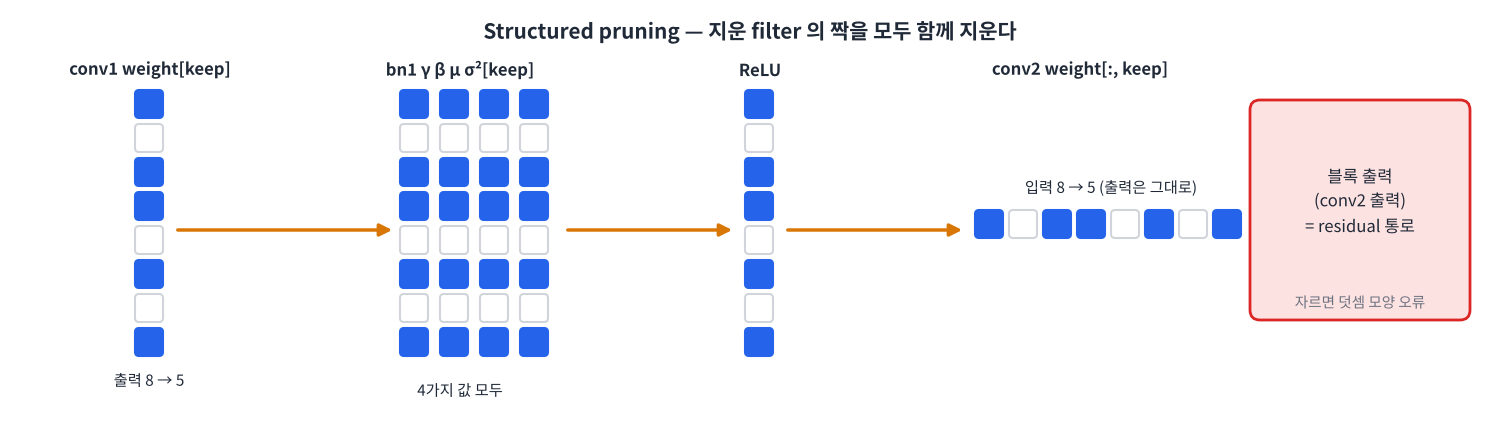

In [ ]:
#@title 🖼 그림 — Structured pruning — conv1 filter · bn1 · conv2 입력 채널을 함께 줄인다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day5/img/f4_struct.png", embed=True, width=860))

**✍️ 직접 구현 4-1** BasicBlock 하나를 받아 **conv1 filter 의 L1-norm 이 큰 순서로 (1 − ratio) 만큼 남기는** `prune_block(block, ratio)` 를 만드세요. 새 `conv1` (출력 n_keep), 새 `bn1` (γ · β · running_mean · running_var 를 keep 만), 새 `conv2` (입력 n_keep) 를 만들어 블록에 넣고, 남긴 인덱스 `keep` (오름차순) 을 돌려줍니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 4-1 — 실행할 때마다 하나씩
show_hint("4-1", "bl9rZWVwID0gYGludChyb3VuZChjMS5vdXRfY2hhbm5lbHMgKiAoMSAtIHJhdGlvKSkpYCwga2VlcCA9IGBmaWx0ZXJfbDEoYzEpLmFyZ3NvcnQoZGVzY2VuZGluZz1UcnVlKVs6bl9rZWVwXS5zb3J0KCkudmFsdWVzYC4eY29udjE6IGBubi5Db252MmQoYzEuaW5fY2hhbm5lbHMsIG5fa2VlcCwgMywgc3RyaWRlPWMxLnN0cmlkZSwgcGFkZGluZz0xLCBiaWFzPUZhbHNlKWAgwrcgYHdlaWdodC5kYXRhID0gYzEud2VpZ2h0LmRhdGFba2VlcF0uY2xvbmUoKWAuHmJuMTogYG5uLkJhdGNoTm9ybTJkKG5fa2VlcCkudHJhaW4oYjEudHJhaW5pbmcpYCAo7IOIIOuqqOuTiOydgCB0cmFpbiDrqqjrk5whKSDsl5Agd2VpZ2h0IMK3IGJpYXMgwrcgcnVubmluZ19tZWFuIMK3IHJ1bm5pbmdfdmFyIOulvCBgW2tlZXBdYCDsnLzroZwgKGBnZXRhdHRyYCkuHmNvbnYyOiBgbm4uQ29udjJkKG5fa2VlcCwgYzIub3V0X2NoYW5uZWxzLCAzLCBwYWRkaW5nPTEsIGJpYXM9RmFsc2UpYCDCtyB3ZWlnaHQg64qUIGBjMi53ZWlnaHQuZGF0YVs6LCBrZWVwXWAgKOyeheugpSDstpUhKS4=")

In [ ]:
# ✍️ 직접 구현 4-1 — 블록 안쪽 채널 줄이기
def prune_block(block, ratio):
    c1, b1, c2 = block.conv1, block.bn1, block.conv2
    # TODO
    pass

blk = copy.deepcopy(rn20.layer2[1]).eval()
x_ = torch.randn(2, 32, 16, 16); y0 = blk(x_)
keep = prune_block(blk, 0.5)
print("keep:", keep.tolist(), "| conv1", tuple(blk.conv1.weight.shape), "| conv2", tuple(blk.conv2.weight.shape), "| 출력", tuple(blk(x_).shape))

In [ ]:
assert tuple(blk.conv1.weight.shape) == (16, 32, 3, 3) and tuple(blk.conv2.weight.shape) == (32, 16, 3, 3) and blk.bn1.num_features == 16
assert blk(x_).shape == y0.shape and keep.tolist() == sorted(keep.tolist())
_b = copy.deepcopy(rn20.layer2[1]).eval(); _y = _b(x_); prune_block(_b, 0.0)
assert torch.allclose(_b(x_), _y, atol=1e-5)
print(f"✅ 블록 안쪽 32 → 16 채널 — 블록의 입출력 모양은 그대로 (ratio 0 이면 출력도 똑같음)")

In [ ]:
#@title 🔒 정답 보기 4-1 — 강사가 알려 준 실습 4-1 잠금 코드를 입력하세요
show_answer("4-1", (
    "f0HUuPB4LY400gdHR7xkU1MqH2sAmdD4aQzX/ssi7cE0nLQIQ3SnohoBB1bzZq9mToDHQfkI1Ed8z6GT4NFAoeSi"
    "+Hd+f6PgG60OxRgZSa5lrNWcSvnfPYnMy2xssSjg4nPTdYDK7QhrHUfP61CQOZ0deycFfTjrQyHDOhEtn5BqqscV"
    "MFcLLVdZ2q5he6yJC90ZKw2vKvEo7VH0trnywzEAMqZ/oqAyIvv5umJ1EvPzemHw7U5kwLdAjsHNc9Bfl6OaaW9h"
    "/l9ZVSweqvkv9+gehJoASjJPJC5RiFQpwZyOzLuM8vlkloC+m/zMLs2bzbkZQvONBXNY6HULXdKrWRaSMM+FEcp9"
    "ewTtipkSXuzle1cAEjOzS5U3O8TmS+zRW/VHa12lyy4T/f1PNtBKCRtSpHhe0N0AR/on0pryYB0WSOmnvEtpLbH0"
    "0tmrw1ma4D8gdEZQTCNJg2IR1r7HGy072Xc8OuJK7mgoBNnI3P+fSdcVCpHawes+MvgYtH21Kq3rRaMGsxjvTPEb"
    "c4UrbMqIvC9Rt64MrEQQQjOq9BAj7+H5H7JUIV719tyuu7oLlQ6V4S4NulIfTx1RQnDMR5oDLR26XJKrnKMl+xxn"
    "cgBzfApRcUJCsnkLPcu8meMq4w4fjt3tvY5iwWLaHAPVQzeoDVrGs6NE4rM5GML7sc3AaBnE+JcId5qDoIfn3+dQ"
    "KsHz1kmm27iEuftoTdnlO/wPk4FY89t5MWzKvd0cveEU93/ZE46fqG7DSEDo8rCw2IzsVJtR9Z1/qubJNL7/5uge"
    "UhfXWcFdThi8kw/7CP3Hq4SIfgF2lE8wjzyyoA1DD3XGMk7eFpi+VROvh313tVvTeJj9pRPSnmeAxxWPF79zWxBd"
    "QapJrIbupAB3fI32buE+LM+JR8b4F73503ogozocVdw3u+QSvwsuAhrk+2lciVBDNcxtsVNR48EkF0addSPwrkny"
    "bcnIY6jvWUqxdL0n7bWVA3zvqxYjLMlftyKngxg9gSwGRKw+WaJwZEI8ufcmezwRiUsoD41l5fc8Ur+hrnoOBGTO"
    "r8fHI8uyDQ/2b8K3irvp2/kRo5aO6SH6Fu5oL3iA/H+1T/410M9vUekDR3t0tICBcJWHi/pPi5B2TWggEjcWV2x2"
    "v0P5yL42kGERE4phZyA4o2mWO2GxcrbGJWUxYZJHxXiThvtIicrCZ6EKxCZw3oQsdtVzzal6x6mvNY+WTvIuXV6a"
    "L/M1kMJu+DUn/nmBe+x5sD2RjQLfzMw4vzK70ZAjfmvk/lzXL1YeNcWLxO5Ecfgz0OC9xWuI8HzMgDJXrsDLFO11"
    "2F62NaeFHYf6q3btX8HFGN+RIjSfVNPUwGBG9o1W4huabdS1ilRfiRieO/K+FcEIsOtQczxvidydIJzDqgpf1WGM"
    "51GlqEy6RZzSCgza4Iuuj4jv+8xmFbUTIHNYxTG7hktXcWl6ghuq2CAyb5xZuGkiuvCrxC96LSyh1NyMcZop/IAA"
    "wBXvFm8srBqk4FW79anPrxLLTq7yo2ND+6pU+SABH4+o1WHxwW58mOvf5nxsj49Po5WurYDfCyEZBiVshb5Px034"
    "PpNCZtSbwOrof6Plz4APajd/px87hKbftDp7Nqxx+RqBEj0kksio8GhptIKWqaY1ABOaee+7rpiPdmM9Npc50s6o"
    "8T/wanNZOxDHxr3i956NmMJixZ6GQXFqAU85nZB71U+JhrQyJN7PugX33OLliddbfrqZIwjPmBx78vrtJwQShQ6P"
    "Q+owUyn1jmZaIvEnNKx04HRY29YT6LKHDfF0eHmR7d0zWIXiGdH4MM3JxVHBJ+Nmrn/IUVgEJ5N/9/V9LyhacD1v"
    "5zugCLsQmxdUOW/bjpcuVqVdDlgDFWtLrrLnzcrXhC/ueyf4IrYKrAxRJkuuCOPLLyWCzLSCZAtjtE7yELPpCatq"
    "Uc60ehTbFuBtKYOHBzco9PUEOzfBvnvQG9I/Y2KIUE53JxNGwzamS10fF/fAHZfWoN1muE5DaT50WrItgypOBmim"
    "gdOkrO9VnukI04k7Tq6HRmbaNctkbb9ZkUFRnFcxf6BtZINmQkU0iZdsZzxE/gE1MoR8Luk7RE9x9Bno09xdsqiU"
    "rzYuRdUXKxNzrz2M2/tdJXEFIVQ46/A1kZYDxRHJpRi/37WgCRXw4Gh7T717RRPIMuwG3wxFjTWbJNAQXq/0FQwR"
    "53xZXqcYGAalr7AozwVL6EeLfbqVVInRa3V/ILNVkNYHliMfIIrzRnddGLRs4005Y8SR8DCBZOjHD3BPh8rNyvyB"
    "M9dF+buUcxInO1Qk62Lq3wyLa1LFWsXxgLe4shasSsr7+3uOV+GYDQg4imRiSlDPnZ8OxAANgldHHftULYIUfLMh"
    "zPgk2vf1ezs/ppxvHbw="
))


**✍️ 직접 구현 4-2** `rn20` 복사본의 **9개 블록 모두**에 `prune_block(block, ratio)` 를 적용한 모델을 돌려주는 `manual_prune(model, ratio)` 를 만들고, ratio `[0.25, 0.5]` 각각의 params · 정확도 · PyTorch 지연을 `manual_df` (열 `ratio, params, acc, latency_ms`, 첫 행은 ratio 0 = 원본) 로 만드세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 4-2 — 실행할 때마다 하나씩
show_hint("4-2", "YG0gPSBjb3B5LmRlZXBjb3B5KG1vZGVsKWAg4oaSIGBmb3IgbGF5ZXIgaW4gW20ubGF5ZXIxLCBtLmxheWVyMiwgbS5sYXllcjNdOiBmb3IgYmxvY2sgaW4gbGF5ZXI6IHBydW5lX2Jsb2NrKGJsb2NrLCByYXRpbylgLh7tlok6IGB7InJhdGlvIjogciwgInBhcmFtcyI6IG5fcGFyYW1zKG0pLCAiYWNjIjogYWNjX3RvcmNoKG0pLCAibGF0ZW5jeV9tcyI6IGxhdGVuY3lfdG9yY2gobSl9YCDigJQgciDsnYAgMC4wLCAwLjI1LCAwLjUu")

In [ ]:
# ✍️ 직접 구현 4-2 — 9개 블록 모두
def manual_prune(model, ratio):
    # TODO
    pass

rows = []
# TODO
manual_df = pd.DataFrame(rows)
display(manual_df.round(4))

In [ ]:
assert manual_df.ratio.tolist() == [0.0, 0.25, 0.5] and manual_df.params[0] == n_params(rn20)
assert manual_df.params[2] < 0.6 * manual_df.params[0] and manual_df.acc[2] < manual_df.acc[1] < FP32_ACC
print(f"✅ 블록 안쪽 50% — params {manual_df.params[0]:,} → {manual_df.params[2]:,}, 정확도 {manual_df.acc[2]:.3f} (fine-tuning 전)")

In [ ]:
#@title 🔒 정답 보기 4-2 — 강사가 알려 준 실습 4-2 잠금 코드를 입력하세요
show_answer("4-2", (
    "8MqGJOAy51gDBiiczbJJIo8J6SYDbEIzy3Dls6NG+uRJFVBthYEoQOz6VaoSAWc4BdeLY+Zc/ca8wFdqJ13FOuTs"
    "HBlPccanaqiM1g7jCb9fxD6HHTKpfklV/V0bzewTWRKxwWj3YW4ztDCi8cVx7JjhMwMeVEtamdKx8LeTCCaIJYt0"
    "BpCNSkdhaDuPle45edoXv4kUpDgyukdiguXKdSaZJ9MaXDirGHDg+aUEx95uECx4/5cN+eijhEcXmGRuESE6KTjA"
    "qxRKC3p6E2GlkO8cMVewaXbg1AmZbgB7QjfCL/mOBKPXmb22M/udse3k3SlCUqt92pdc7Oy1y7e+567GOaOH85Vw"
    "/b9Nh6KMOh+4U62dfxsFlQxx+DdDbIa2754a2AHI2SDjSDoSrKZ0bnIiyg7QwvqW7ZYRCeeV44dvvrCCOCkuINmo"
    "Od0Mghx4UDubVPuh77eKdGm68SHEMXkRhl2bZKRI8/pJEleK5G2++pCDW/r8i1gwh+9QHZfDlB0YtzOFxo8eXpTe"
    "6yGYgfKcCdCbYTRHsAkYO2bR4YzEao6xnTUjzRu5ofbiZ1e7ce7Y+y+EmAQiL7wg/vcbodRLodyXUyKpyeMcKXJe"
    "QKpiks2M1oPpaJCavLinc4uR9OoCmqtAA4VymdpMJ0WQSb/6SEtySf2EMRBQ/bqNxeOXmahNGUk4B4JY5PF5dGXk"
    "i+wsZqC+Tjb14WPrr9oGeoNcHlq4b/VQ/VkwF5YEg/tQdwP/81NsBk1CPDUNBTl9MGVyxWWWfLUpssX3ZW3xVF2N"
    "IlDUSJnmzLjKU4RSzXguzUm1/MjB0MabyGLT4nWIhECgZTEPfbom9U20ysfp1u/ZLw+O4oluiyghbC06FB+BMOGa"
    "TgaDrL/MmIaU8ieB2A3kgl2oH3Q68XcpRflUrSx0UjXkW/apE0w4aSuUcDFl+cnbPaxpZ9KjEYQgfgzpeX7/AayM"
    "D9t8GvRFVELUTmMyPb6ZF0FY/J2NIWkMl6lG726RNuO/H298h7cWNiNnoNnkt6wtxO6YeCdG/PvXwXcyWb0Zngb2"
    "lIpztC5PPyuvFQocoP+o790+Tx1A3KNXjHpkt/WMBQjfsNOVUf3OK8GyA3i16P1f"
))


**▶ 예제 4-A (제공 코드 — 실행만)** (1) `manual_df` 의 지연으로 ratio 0.5 의 속도비 `speedup_manual = 원본 / 50%` 를 구합니다. (2) 블록의 **conv2 출력 채널** 을 자르면 무슨 일이 생기는지 봅니다: `rn20.layer1[0]` 복사본의 conv2 를 출력 8채널짜리 Conv 로 바꾸고 (bn2 도 8채널로) forward 해서, 나는 오류 메시지를 `err` 에 담습니다.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 4-A — 제공 코드 (그대로 실행)
speedup_manual = manual_df.latency_ms[0] / manual_df.latency_ms[2]
b_ = copy.deepcopy(rn20.layer1[0])
b_.conv2 = nn.Conv2d(16, 8, 3, padding=1, bias=False); b_.bn2 = nn.BatchNorm2d(8)
try:
    b_.eval()(torch.randn(1, 16, 32, 32)); err = None
except RuntimeError as e:
    err = str(e)
print(f"블록 안쪽 50% 속도비 {speedup_manual:.2f}배")
print("conv2 출력을 자르면 →", err)

In [ ]:
assert speedup_manual > 1.1 and err is not None and "size of tensor" in err
print(f"✅ unstructured 90% 는 {speedup90:.2f}배, structured 50% 는 {speedup_manual:.2f}배 — 그리고 residual 덧셈이 모양을 막는다")

> 💡 **예제 4-A 해설** — 강사 실측 (CPU): 블록 안쪽 50% 로 1.72 → 1.36 ms (1.26배). conv2 출력 (8) 과 shortcut (16) 의 덧셈에서 'The size of tensor a (8) must match the size of tensor b (16)' 오류가 납니다. 바깥쪽 채널을 자르려면 shortcut · 이전 블록의 conv2 · 다음 블록의 conv1 입력 · stem 까지 같은 채널을 함께 잘라야 합니다 — 사람이 하기엔 실수하기 쉬운 일이라 도구 (5교시) 를 씁니다.

#### 📌 4교시 정리

- filter 를 지우면 **conv (출력) → BN (4가지 값) → 다음 conv (입력)** 를 함께 줄여야 한다.
- structured 는 같은 비율에서 정확도 손해가 크지만, **텐서가 진짜로 작아져 바로 빨라진다.**
- residual 덧셈은 '같이 잘라야 하는 채널 묶음' 을 만든다 → 의존성 그래프가 필요하다.

## 5교시 — torch-pruning: DependencyGraph · MetaPruner · MACs

[torch-pruning](https://github.com/VainF/Torch-Pruning) 은 예시 입력 하나를 흘려 **연산 그래프를 따라가며** "이 채널을 자르면 함께 잘라야 하는 모든 곳" 을 찾아 줍니다.

| 도구 | 하는 일 |
|---|---|
| `tp.DependencyGraph().build_dependency(model, example_inputs=x)` | 그래프 추적 → 층 사이의 의존성 기록 |
| `DG.get_pruning_group(layer, tp.prune_conv_out_channels, idxs=[...])` | 그 채널을 자를 때 함께 바뀌는 **묶음 (group)** |
| `group.prune()` | 묶음 전체를 한 번에 자름 |
| `tp.pruner.MetaPruner(model, x, importance=..., pruning_ratio=0.5, ignored_layers=[model.fc])` | 모든 묶음의 중요도를 매겨 **비율만큼 자동으로** |
| `tp.importance.MagnitudeImportance(p=1)` | 묶음 안 weight 의 L1-norm 합 = 중요도 (4교시의 filter_l1 일반화) |
| `tp.utils.count_ops_and_params(model, x)` | **MACs** (곱셈-누산 횟수) · params |

> `ignored_layers=[model.fc]` — 마지막 fc 의 **출력** (클래스 10개) 은 자르면 안 됩니다. `pruning_ratio=0.5` 는 채널 수 기준이라 Conv 의 입력 · 출력이 모두 줄면 MACs 는 약 **(1 − 0.5)² = 25%** 로 줄어듭니다.

> 🎬 **애니메이션** [D5-5 torch-pruning](https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/animation.html#d5-5)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

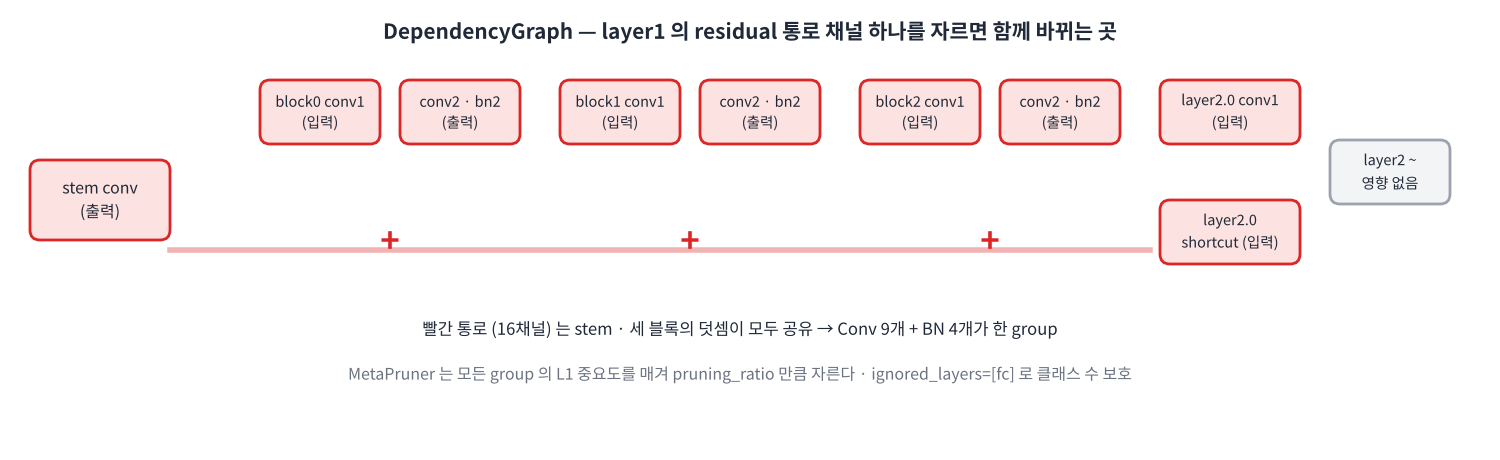

In [ ]:
#@title 🖼 그림 — DependencyGraph — residual 로 묶인 채널은 stem 부터 다음 stage 입력까지 함께 잘린다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day5/img/f5_depgraph.png", embed=True, width=860))

**▶ 예제 5-A (제공 코드 — 실행만)** `rn20` 복사본 `m_dg` 로 DependencyGraph 를 만들고, `layer1[0].conv2` 의 **출력 채널 [0, 1]** 을 자르는 group 을 구합니다. group 에 든 **Conv2d 이름** `group_convs` 를 출력한 뒤 `group.prune()` 하고 정확도 `acc_dg` 를 잽니다. 채널 2개를 자르는 데 Conv 몇 개가 함께 바뀌는지 보세요.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 5-A — 제공 코드 (그대로 실행)
m_dg = copy.deepcopy(rn20).eval()
DG = tp.DependencyGraph().build_dependency(m_dg, example_inputs=EX_IN)
group = DG.get_pruning_group(m_dg.layer1[0].conv2, tp.prune_conv_out_channels, idxs=[0, 1])
group_convs = sorted({it.dep.target.name.split(" ")[0] for it in group if isinstance(it.dep.target.module, nn.Conv2d)})
print(f"group 항목 {len(group)}개 · 그중 Conv2d {len(group_convs)}개:", group_convs)
group.prune()
acc_dg = acc_torch(m_dg)
print(f"자른 뒤 — stem 출력 {m_dg.stem[0].out_channels} · layer1[2].conv2 출력 {m_dg.layer1[2].conv2.out_channels} · layer2[0].conv1 입력 {m_dg.layer2[0].conv1.in_channels} · 정확도 {acc_dg:.4f}")

In [ ]:
assert {"stem.0", "layer1.0.conv2", "layer1.2.conv2", "layer2.0.conv1", "layer2.0.shortcut.0"} <= set(group_convs)
assert m_dg.stem[0].out_channels == 14 and m_dg.layer1[1].conv2.out_channels == 14 and m_dg.layer2[0].shortcut[0].in_channels == 14
assert acc_dg > 0.4
print(f"✅ 채널 2개를 자르는 데 Conv {len(group_convs)}개가 함께 바뀜 — layer1 의 residual 통로 전체")

> 💡 **예제 5-A 해설** — layer1 의 세 블록은 모두 같은 '통로' (stem 출력 16채널) 에 덧셈으로 연결되어 있어서, 한 채널을 자르려면 stem · 세 블록의 conv2 (출력) · 세 블록의 conv1 (입력) · layer2[0] 의 conv1 과 shortcut (입력) 까지 9개 Conv + BN 4개를 함께 잘라야 합니다. 4교시에서 손으로 하다 오류가 났던 바로 그 작업을 그래프가 대신 합니다. 강사 실측: 채널 2개만 잘라도 0.846 → 0.634 (통로 채널은 모든 블록이 쓰는 중요한 채널).

**✍️ 직접 구현 5-1** 모델을 **복사**해 `MetaPruner` (L1 magnitude, `ignored_layers=[fc]`, `pruning_ratio=ratio`) 를 만들고 `step()` 한 번으로 자른 모델을 돌려주는 `prune_channels(model, ratio)` 를 만드세요. 50% 모델 `p50` 의 MACs · params 를 원본과 비교한 `count_df` (열 `model, macs_m, params`) 를 만드세요 (`macs_m` 은 백만 단위).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 5-1 — 실행할 때마다 하나씩
show_hint("5-1", "YHRwLnBydW5lci5NZXRhUHJ1bmVyKG1vZGVsLCBFWF9JTiwgaW1wb3J0YW5jZT10cC5pbXBvcnRhbmNlLk1hZ25pdHVkZUltcG9ydGFuY2UocD0xKSwgcHJ1bmluZ19yYXRpbz1yYXRpbywgaXRlcmF0aXZlX3N0ZXBzPXN0ZXBzLCBpZ25vcmVkX2xheWVycz1bbW9kZWwuZmNdKWAuHnBydW5lX2NoYW5uZWxzOiBgbSA9IGNvcHkuZGVlcGNvcHkobW9kZWwpLmNwdSgpLmV2YWwoKWAg4oaSIGBtYWtlX3BydW5lcihtLCByYXRpbykuc3RlcCgpYCDihpIgYHJldHVybiBtYC4eYG1hY3MsIHBhcmFtcyA9IHRwLnV0aWxzLmNvdW50X29wc19hbmRfcGFyYW1zKG0sIEVYX0lOKWAg4oCUIG1hY3NfbSDsnYAgYG1hY3MgLyAxZTZgLg==")

In [ ]:
# ✍️ 직접 구현 5-1 — MetaPruner · MACs
def make_pruner(model, ratio, steps=1):
    # TODO: MetaPruner 를 만들어 돌려준다 (6-2 에서 steps=3 으로도 씀)
    pass

def prune_channels(model, ratio):
    # TODO
    pass

p50 = prune_channels(rn20, 0.5)
rows = []
# TODO: FP32 · structured 50% 두 행 (model, macs_m, params)
count_df = pd.DataFrame(rows)
display(count_df.round(2))
print("p50 의 layer3[0]:", p50.layer3[0].conv1, "| fc:", p50.fc)

In [ ]:
assert count_df.params[0] == n_params(rn20) and count_df.params[1] == n_params(p50)
assert 0.2 < count_df.macs_m[1] / count_df.macs_m[0] < 0.32 and p50.fc.out_features == 10 and p50.layer3[0].conv1.out_channels == 32
print(f"✅ 채널 50% → MACs {count_df.macs_m[0]:.1f}M → {count_df.macs_m[1]:.1f}M ({count_df.macs_m[1] / count_df.macs_m[0] * 100:.0f}%) · params {count_df.params[1] / count_df.params[0] * 100:.0f}%")

In [ ]:
#@title 🔒 정답 보기 5-1 — 강사가 알려 준 실습 5-1 잠금 코드를 입력하세요
show_answer("5-1", (
    "TAgaSgx2HfHHDokpGxTikjksN/yxqzv9sozEd/YGWDyrJo1QAB7X2BD7qwxj2fEmv4HP64Q56vZTVVVVgi6OSZwz"
    "vM4iloIINHeT3NPpic4bLOeRLpuV7FvsHgqBrhSQRmWhU7Tymjys85DXxhx2mEmE/RM+11yhMnhu+KSmcoa4ynvh"
    "uMsFQB43oY1/iZqM8Kcb5HM4AMCabARRazMrwXGRKjEj7AawhWxa5032CA9i/qx9d1qRIJlouY+slmVxzSB5/3qR"
    "BGvemVpLkwvMUXYLhqJ6MbE4yEHiA8XvYfE/3UEo0bYnPKaVO2XY7zOFoA9KPFgcRcHgq7Uiy2U0JEHgvXdDVIDK"
    "RDBs7+3mtRlsJVMOj+DOz9T9jFNx+1IS6biHFlP8wlvqe8MRBudIqa2WgGfeVkY/VmWKe3hgyP/2yQHBfbDhqkwL"
    "LhQWkYdioxxWQRkLfx6aMEOl0BIIhFgR90TRuNS0Gsn6sJPblIAXMUvbwJxBvgqgFAK/C6jFoP2siNhloqjIl37G"
    "zik1yrwXIwWtZ0OwT4eIqmu93B0vdDyCObVN3kq7jA50S94dXvC4VLbHSwjE+tgCbZ6a96VybXtRVKnV87OQgs9y"
    "ZsBx4TQCYIuu3jAMhjs8Pmjra2huiC8UoLN+utzlJbtZ9/IgmmEELAQ40YbOzOPbIyCNs/cGzjqZ+T9xh5Tpx3SD"
    "N9T4xN347o8BfRTwVSs5k6n15UlQnZ+Fjw2ejER8+6/OVMX6i1w1hllNtTuc/jZ/9mbSWqohygIZn1Av6m6wTQdl"
    "ASj9BPsrzAbeam3YCxrqUsPkPK1Ay6S2yhm9TrOAQW+1Hb40KKEDug2SdxSpNV3cbJlX5JOOcbTsE1QrQcybsS1f"
    "3GAHyIHC6aqt+8a0ZVXTUFkMz2kh8+Rza9cwA9t0eGUM2tmOPfN3a7+EsOLXadRXpTLEsSo3sfyq6aUZ8OarjcgF"
    "A+anaLJh3wtAT4GlMaD4vx6QIWYD8N8W6lzelvCsaxWyJo2Z81ThaDVpWi3nOXBzKPka0TYjU8jb/ZSgly056mco"
    "9ndPOwyigQaY6Y1WPIOWkqFs7z/rDZkvN8xHgcVEXof9o3/hkUzbohBTSFFC6sUMN5shan9MD1uTAH6hf0JMcid6"
    "4A53WxdMd0e0FhkjEwiVBKJc27zxq9hoOFAvOlfI0Jl8q/L4k3XYiNa0b9m96YX8OPyU4KaP/ANGi1x5Sv6CzMMt"
    "+HQQIVNqzlKtylLiL39X6slazrz53u0pHag28zbikkjwL+czRiajPQJn/SKHyBBJkjm8y39bNTwuFibj+VV5rMy2"
    "JGbvUyp9uwVk4sumYZfRkFgq2RsyHdcIa+qbDr+96cRQtuN/T0EfKcyzQObyfSh9O9hhESzbIB2IVfV6AHmgc0fI"
    "+rp/7tHDmoUcACmZNCBXrfsf0IhOROOcBdpcs/V3"
))


**✍️ 직접 구현 5-2** ratio `[0.0, 0.2, 0.4, 0.6]` 각각 `prune_channels` 한 모델의 MACs (M) · params · 정확도 (fine-tuning 전) · PyTorch 지연을 `tp_df` (열 `ratio, macs_m, params, acc, latency_ms`) 로 만드세요. ratio 0 은 원본 `rn20` 을 그대로 씁니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 5-2 — 실행할 때마다 하나씩
show_hint("5-2", "YG0gPSBwcnVuZV9jaGFubmVscyhybjIwLCByKSBpZiByID4gMCBlbHNlIHJuMjBgLh7tlok6IHJhdGlvLCBtYWNzX20gKGBtYWNzIC8gMWU2YCksIHBhcmFtcyAoYGludGApLCBhY2MgKGBhY2NfdG9yY2hgKSwgbGF0ZW5jeV9tcyAoYGxhdGVuY3lfdG9yY2hgKS4=")

In [ ]:
# ✍️ 직접 구현 5-2 — 비율 다이얼 (fine-tuning 전)
rows = []
# TODO: 0.0, 0.2, 0.4, 0.6
tp_df = pd.DataFrame(rows)
display(tp_df.round(4))

In [ ]:
assert tp_df.ratio.tolist() == [0.0, 0.2, 0.4, 0.6] and tp_df.macs_m.is_monotonic_decreasing and tp_df.params.is_monotonic_decreasing
assert abs(tp_df.acc[0] - FP32_ACC) < 1e-9 and tp_df.acc[1] < FP32_ACC - 0.2 and tp_df.latency_ms[3] < tp_df.latency_ms[0]
print(f"✅ 60% → MACs {tp_df.macs_m[3]:.1f}M · 지연 {tp_df.latency_ms[0]:.2f} → {tp_df.latency_ms[3]:.2f} ms — 하지만 정확도는 {tp_df.acc[1]:.2f} 부터 무너짐")

In [ ]:
#@title 🔒 정답 보기 5-2 — 강사가 알려 준 실습 5-2 잠금 코드를 입력하세요
show_answer("5-2", (
    "re6glrYUpoDL2E4Txc4ZzT8idwDNKWfJUpDBBCPQpduLm9zFVS6SQeJutNZrBpsALZiuJ312P/Kw6k8BxGxaFDKE"
    "ipbgAQNmYWDNq6n2rRgSiRcC6jlNoqdWm+7HqBQK03ykGkdV3nTnbnO0udeNI+ExfXQXirQu4LTv6qqnfogKY25u"
    "iSYWnS5t4aF2QP7ddNQ7TIxLTINMfNFh90ZBXmR9f4MZL2EV6JYv+FtrpAUvq7nGKzqcZnveRW5srkG0LbWexNj0"
    "L2u5zr7f652p/X0JBebz3dqCyqM48fG44yWLx+GWSQ9nmkY+u5E1iKgl02/j4Ue3u89aoH45ZdxJtXsKWTxhkoJf"
    "OgSJC5G6C6p6VgsN5r8RFXbPgxv2dEgONF6wuniROh3S8AEOl9nMmpWuGaSfl3m0UEEMr3LAVEQ07Ehd92Xy/ljD"
    "qDHDzBS1LRI1zo35oEdfoJBQTn1ABhcFY1qwPwTc11N/pPw+goUFXAfg8koZ9k5d0hWyke7IJOW5pqBQTNbHsQEM"
    "SGyJ2PBSUx4+mTsTsRTvwT0AmQXIz56dMpak2AMN4+DWLhyJjQvr6O0gainWC7LLrQUgFuzo3QcSgtYV99OM5P90"
    "dCi7Iph1enolx7m+OenlA33MRDFizriHjWZMvGCsxsVAQ+jtVZ9on42IkLzlZqb7maQBT31CjaQ1zeEFg1+dBvJo"
    "8SRLkKQfBtJsBthEAmS1E+8j/VKou5uMrcybwgn2oBRYHxfGsDbz0OMVYb5hcvtVi6abvWPirLESnIlabUtMu44m"
    "NA0AQQF9BpYM82mBoBO6yxNhGAnDQDO/bB4uLWKAd1YQeysez+aJM5g3AWTj+NSZ8EaZ9bsx09ok6joTlh5ulMKd"
    "BcT1u2buPePAe27uMVQrXc2MdOYaa5lQbSCUFLujDw7SXuoNbfNDGGEl5rdamfdDK+7WFk5WS8YGUV83Vu2fYLcS"
    "wyDeE/0SDHT3YZo7WijXAcMITCjEQriffJlNtpvG1mrRvU3LM+YNjHxHesAi03Yui1Sq9gC1PpqcnRkoEJ7VZ0IS"
    "vpTodQBJqBe07bG+9GSIw0BMWJeAqBqCGpXKiykypXoHYFSLh4oPl5uh5bkidNJ+7WnB4MIeebzgxXWYvjK0HGNy"
))


#### 📌 5교시 정리

- DependencyGraph 가 residual 로 묶인 채널을 찾아 **함께** 자른다 — 사람이 하면 틀리기 쉬운 일.
- MetaPruner = 모든 group 의 중요도 (L1) 를 매겨 비율만큼 자동으로. `ignored_layers` 로 fc 출력을 지킨다.
- 채널 r 만큼 자르면 MACs 는 약 (1 − r)². 지연은 줄지만 fine-tuning 전 정확도는 무너진다.

## 6교시 — Fine-tuning · iterative pruning

잘라 낸 모델을 학습 데이터로 **짧게 다시 학습**하면 남은 weight 들이 빠진 채널의 역할을 나눠 맡으며 정확도를 되찾습니다. Day 4 의 `train_qat` 와 같은 루프입니다.

| 설정 | Day 4 QAT | 오늘 fine-tuning |
|---|---|---|
| 데이터 | 학습용 10,000장 · 증강 | 같음 |
| 최적화 | SGD momentum 0.9 · cosine | 같음 |
| learning rate | 1e-3 (거의 다 된 모델을 살짝) | **1e-2** (크게 망가진 모델을 다시 세움) |
| epoch | 3 | 3 |

| 방식 | 하는 일 | 특징 |
|---|---|---|
| **one-shot** | 목표 비율까지 한 번에 자르고 → fine-tuning | 간단 |
| **iterative** | 조금 자르고 → fine-tuning → 또 자르고 → ... | 한 번의 충격이 작음. 보통 같은 총 학습량이면 비슷하거나 낫지만, **총 학습량이 늘어나야** 이득이 분명해짐 |

> 오늘 만든 **50% + fine-tuning 모델 (`rn20_p50_ft.pth`)** 은 내일 (Day 6) 지식 증류 (KD) 의 학생 모델로 다시 씁니다.

> 🎬 **애니메이션** [D5-6 fine-tuning 과 iterative](https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/animation.html#d5-6)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

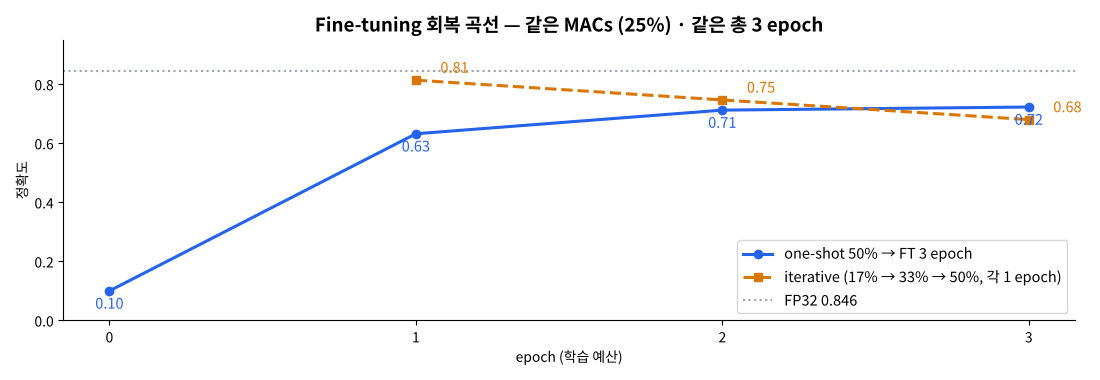

In [ ]:
#@title 🖼 그림 — Fine-tuning 회복 곡선 — one-shot vs iterative (같은 3 epoch)
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day5/img/f6_ft.png", embed=True, width=860))

**✍️ 직접 구현 6-1** `finetune(model, epochs=EPOCHS, lr=1e-2, on_epoch=None)` 을 만드세요 (Day 4 `train_qat` 와 같은 구조: 모델을 `DEV` 로, SGD momentum 0.9 · weight_decay 5e-4, step 마다 CosineAnnealingLR, epoch 마다 `on_epoch(ep, model)`, 걸린 초를 돌려줌). 5-1 의 `p50` 복사본 `p50_ft` 을 fine-tuning 하며 epoch 별 정확도를 `hist_df` (열 `epoch, acc`, epoch 0 = fine-tuning 전) 로 기록하고, `torch.save(p50_ft, "rn20_p50_ft.pth")` 로 저장하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 6-1 — 실행할 때마다 하나씩
show_hint("6-1", "RGF5IDQgYHRyYWluX3FhdGAg66W8IOq3uOuMgOuhnCDsmK7quLDqs6AgbHIg6riw67O46rCS66eMIDFlLTIg4oCUIOunqCDslZ7sl5AgYG1vZGVsLnRvKERFVilgLh7siqTsvIDspITrn6w6IGBDb3NpbmVBbm5lYWxpbmdMUihvcHQsIGVwb2NocyAqIChsZW4oWHRyX3U4KSAvLyAxMjggKyAxKSlgIOulvCBzdGVwIOuniOuLpCBgc2NoZWQuc3RlcCgpYC4e6riw66GdOiBgaGlzdCA9IFt7ImVwb2NoIjogMCwgImFjYyI6IGFjY190b3JjaChwNTBfZnQpfV1gIOKGkiBgb25fZXBvY2g9bGFtYmRhIGVwLCBtOiBoaXN0LmFwcGVuZCh7ImVwb2NoIjogZXAgKyAxLCAiYWNjIjogYWNjX3RvcmNoKG0pfSlgLh7soIDsnqU6IGB0b3JjaC5zYXZlKHA1MF9mdC5jcHUoKSwgInJuMjBfcDUwX2Z0LnB0aCIpYC4=")

In [ ]:
# ✍️ 직접 구현 6-1 — fine-tuning 회복 곡선
def finetune(model, epochs=EPOCHS, lr=1e-2, on_epoch=None):
    # TODO
    pass

p50_ft = copy.deepcopy(p50)
hist = []          # TODO
t_ft = None        # TODO
hist_df = pd.DataFrame(hist)
# TODO: 저장
display(hist_df.round(4)); print(f"fine-tuning {t_ft:.0f}초 | 저장 rn20_p50_ft.pth ({size_kb('rn20_p50_ft.pth'):.0f} KB)")

In [ ]:
assert hist_df.epoch.tolist() == [0, 1, 2, 3] and hist_df.acc[3] > hist_df.acc[0] + 0.4 and hist_df.acc[3] > 0.65
assert os.path.exists("rn20_p50_ft.pth") and t_ft > 0
print(f"✅ 50% 모델 {hist_df.acc[0]:.2f} → {hist_df.acc[3]:.3f} — FP32 와의 차이 {(FP32_ACC - hist_df.acc[3]) * 100:.1f}%p (MACs 25%)")

In [ ]:
#@title 🔒 정답 보기 6-1 — 강사가 알려 준 실습 6-1 잠금 코드를 입력하세요
show_answer("6-1", (
    "KChRx5HfY6+xJBfR+Ujm3RI/+CB1VP7OR9sDuR1hheDDauJGuI8hLDCuKW8DzCSU1u+wnfsimyeW6s5kjcx6/MWi"
    "/Y1vITZZ+grHgqZvEv+E6GAWnngS85+p9dGx/asLR2nBri+utcTKtY9hN+vAbM2mKhK+omYfxRSVqNfB1+AT39b3"
    "9S4qeghNSSLXuUjg5YuerhgdDRIEeIsrHltCyqTzeGQaQPhPkWFNs4ISFka0Y/GFkEo9AucBRNHzPohs78aH/2zg"
    "8BTlAJR5vv9yhfcOa2EoxA8AXN0p0S8tJxB8wZGqiijgYdisHdoRYCtyoq30ppRzuQz1xlbXY7sV8vzK/ioRaB/Z"
    "BI6534bUJMCZLErtZOB48/Bs+hw8ztTNHpDRdOB3GMrOSc2HZMIhPj89I0OhqbYv4/UUhNGSlpNnpteHSDVJ6akY"
    "2r9xuchXWgG/f85tOu/LbnLCSeiqYEa64CoP6bS/SOBpI8V1GOPOv8kjvPAvmm8DZchiXB8HkslD+APLk66tmUNK"
    "oj3p0Q1ZY3eYby9L8/oEGgMY2d1PuKwI7W5g+sdbTN8P9A2+Z8hoPeW40VJHjcA4k6/N3JQNKtIzfibyi/4yTWJk"
    "Tfz9m8vx2VSabIdqglo87pX1XFphhGt+3IQFUYf1Fb6rVwK36XEzUsGICoL0V+Ex3jw8XaF++Siu4y8hlAzwVnuZ"
    "fEzb/p5qpKB6Wj0N9qFDvyTF5sMh9hGnqlPPT7zwOHoe12d79PTCYwl8KXBCvQ7ZGFZo+K9FDuroa2RYKLR+TRid"
    "X4SVhJZBkLNBh8rCW9o58F8B8BWKXmIYjWwYwX4+j0XGd62wZHBvljk+tSHTzhVlobzyyWQelEgCSvT9mMUeGf/c"
    "Mggji8ZBd+qZHooTId0d0FmriQG2iGcphXkl0u/81i8Nig+9AvifYUSZnp0UF6m9LTWPITZCXwPa8Ovwh3gqig1Z"
    "3+VR/UOdJfmO7yhHzW878s6N6fBPrBLnUv0OUCmrdJjtF3G9Le8l7LRMjg9zXmHyf70uIY/3B+qlgnleoAgpXo0o"
    "QS2S3MU/eeZM8eMn5Ujj1fYh2zN/wfxExL2BEy62vaf4wOwEh2ZGTCiCe+Gaf4/8AbhCAbGLA7H/w6CmQfhK8lcA"
    "j5KJg4kgiiy4sUwARYI6SfS5Dbyt5FyaChsyaOUjC7SuB4ThR6wP09uY3iDNwbAvTDxns9KxGx+BHnwnBYzQxyPb"
    "0EmBhxDsnSCB5JUKjz+TU5qWsBCkFeYZa0Fu0DcBWNzhp9UXg+hFhhmqujjiydetNIPdTWoshHMWWOPEZep/2mxr"
    "Y7mjD/xqpANWbkpW7ESeJ5fzgShMmvmv9nsHJAeGDD04eTfa+RMGKaPtQeHDSHtjX/umYgZSTlhHu7v6hJ1kcvxk"
    "Lt7WC+2/GzbWKnMrVGqOuzgSFr5UL8J6JB+miTHSsyjQMtR1MudSDuPUforxYPKYlf/evtGBFmN7i+c6joq0sQgq"
    "6wtC/ql600qD4tWHh29J6AFyNBXk14ipe7bnBHFvPHOuc1MkS5Rj5omp19FSTv3tOdwdWSyazuYpa8Hwj/JtApCO"
    "1O4kORw/rfjAWf4EbXAhjOhfKfG2kcN+6o7pY8KNiewCEAggqF3HVfEVLNbePzI0fBD7lCbwyGfUYtih4OTdk6dI"
    "eBOoyImFTjakBP/i3bw8PC2BljiKpk47blN4qtEhWQ4n9Naj5Ub/LB4pk5LKTGYyApDFbs8IAl3KtCjQEk8fcTtv"
    "W/BOtCjCgh2exrHYmXe6BwfzcmJtCWwflrUnlX72GU9WS8H7Xr0CI/ieIBoSx8Q/6z/Skp0qxibzyCGEUiWhqec+"
    "cdLGJk6pqGDM0TzgGb3w2qXBqRom55TabcgRx9vP9/4vpVfJY1p2OgG+ENvhKu4AoyXgWYnH20DjASJDWH9MCQvH"
    "a8k7WllPj7D3StRHyFDDxmWYFyLptokopw0IQgVBlZ/iYoQaLxGaICn0an/WWFd+ysloYBROa/NM3kBp74WqfNiI"
    "PBIDRAPt/e2yKT02yULtBbwupLacNjZObS/MiPMa3dRO3NrTOdvzMAbT2u1lJs5ekTrgP9dOAi+BhgqBMSLz5mMA"
    "oMN3bCSqv/X3AG9ora0p1oWLSs6x7V2AOFNJlPvRKyja07nnJE7M6Z8mihBxTNOj9IraNFoRHDyRwuoMnD2UtCOL"
    "0QJye0j6tIwAtomQk+j5NP3ojOPV"
))


**✍️ 직접 구현 6-2** **iterative** 로 같은 50% 를 만드세요: `rn20` 복사본에 `make_pruner(m, 0.5, steps=3)` 를 만들고, 3번 반복하며 `pruner.step()` → (MACs 기록) → `finetune(m, epochs=1)` → 정확도 기록. 결과를 `iter_df` (열 `step, macs_m, acc`) 로 만들고, one-shot (6-1) 의 최종 정확도와 함께 `compare = {"one-shot": ..., "iterative": ...}` 를 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 6-2 — 실행할 때마다 하나씩
show_hint("6-2", "YHBydW5lciA9IG1ha2VfcHJ1bmVyKG1faXQsIDAuNSwgc3RlcHM9MylgIOKAlCBzdGVwIOydhCDrtoDrpbwg65WM66eI64ukIDAuNSDsnZggMS8zIOyUqSDrjZQg7J6Q66aF64uI64ukLh7rsJjrs7Xrp4jri6QgYG1faXQuY3B1KCk7IHBydW5lci5zdGVwKClgIOKGkiBgY291bnRfb3BzX2FuZF9wYXJhbXMobV9pdCwgRVhfSU4pYCDihpIgYGZpbmV0dW5lKG1faXQsIGVwb2Nocz0xKWAg4oaSIGBhY2NfdG9yY2hgLh5jb21wYXJlOiBvbmUtc2hvdCDsnYAgYGhpc3RfZGYuYWNjLmlsb2NbLTFdYCwgaXRlcmF0aXZlIOuKlCBgaXRlcl9kZi5hY2MuaWxvY1stMV1gLg==")

In [ ]:
# ✍️ 직접 구현 6-2 — iterative pruning (3단계 × 1 epoch)
m_it = copy.deepcopy(rn20).eval()
pruner = None      # TODO
rows = []; t0 = time.time()
# TODO: 3번 반복
iter_df = pd.DataFrame(rows)
compare = {}       # TODO
display(iter_df.round(4)); print({k: round(v, 4) for k, v in compare.items()}, f"| iterative {time.time() - t0:.0f}초")

In [ ]:
assert iter_df.step.tolist() == [1, 2, 3] and iter_df.macs_m.is_monotonic_decreasing
assert abs(iter_df.macs_m.iloc[-1] - count_df.macs_m[1]) < 0.5 and compare["iterative"] > 0.5
print(f"✅ 같은 MACs ({iter_df.macs_m.iloc[-1]:.1f}M) · 같은 총 3 epoch — one-shot {compare['one-shot']:.3f} vs iterative {compare['iterative']:.3f}")

In [ ]:
#@title 🔒 정답 보기 6-2 — 강사가 알려 준 실습 6-2 잠금 코드를 입력하세요
show_answer("6-2", (
    "7lHfwID2U1LrWLDiEohFuI4KignUN4uiPEhb0QfY816Bp6sx5oRZB5Oga2hmhXaPQ6h+T2ORZquk7ocqfnSmkVrr"
    "P0yD5UyhLWVZXa+TSrxCNkTtn6jo6y8PgzvuLUUaIL/xuUhOc6lV0XKKfMaEJfKwl0OsbdqB8NZGhe/p4bZy5y1s"
    "mWn/Dk8ZYWngUQqYOsM24rnlZV9ekJ5zMaSNPy2kCPNGUsIO+NO2lvjJbYkDYubmhoblmuxayii+a00s6P2y33W/"
    "q7qpnnHi3DSU13prISDTAOlEs4HcjwoGPzsLP5PtB8MbWOSxAErGfuci3nlwURvjKNpCZbBtF+5WxFuxQnnOO7YI"
    "etyqS5kN0QjTyJlzomKgRMdkf5re3gL6ltJtKp8s7y74V+V6h5wr8ka3/BKZ+oWRUlSitkxyMnv53oCjWW3VZ5nt"
    "AOwqIEGIXgSoTMcdSsdCRC/cOmmdvMwLlppw/2G4rbYKeE4MNBKsyimPmLIMZQ8JBU3aN8XUPx2wSMVOFFDZAH6+"
    "2BPmbssjL3Xgy6JuYrA6zGr5snA0ZdtZxJ5tTphUhHJJVdhMQCEhFxw8H675kfkiNOG1jIWigmINCwmT0jvdwgLe"
    "F/l1VzXm+exAayHk8gYm4C7pj98I9srOLynkA3hLM6xbTbIIt0tC4qi4PZ7IOR+DFUtQtnkkAQwnP6Jj3cTKLnPw"
    "FKPO0Fwf8+CvCN/E9u4eWOkkn0GKS0cx6Vr+V5opVtxfG2ebdifb/vpZ0PlIPUl/DDa+yla5ocBVWwHyAg9C7qNJ"
    "AlDJfTLVA321Ifg60egdeTW7vM4l32XHkV4rBLMYFGMsYkv8VQ61AA0Rk/oSYPYhZkaK5gPL0Yo4RxKpE0IHn8Kn"
    "XibvFliFfBtDKOI/S2G9ZidYxu4bFRMRZoiTCxIjbPkBxQ8b/Sm9rcFp4UdpLKqXpNVuK3g5Tb2f26xUnCfEhNT5"
    "1FS6t1heGPvpPnMhzE2w/lu1vJ6kYfIqw93YVZPndJQ8vGfOCiEvg51Aec2hiEuyrES/38CDbHV8lFjxgg/MHpLY"
    "qqJFnzZWG6m2C1F8+fFe69YnOpP2xSUPztaLy8olPHAM57yyo481tN7Of/S81/hAjbLD9Np/wiczbGpsu7V3D8hw"
    "/p/WblEeQrW3ezjwNQQpJ3eoryJUcetdB5LJdm0QtLZamuz+89LR73YW6ujQ02QWftIWYirUwpbjFttaOaKP+OLB"
    "hAln/XI4S3Fpp1bjQFkyiEOHtk0F49WaBdNsWSGOhBqoWGUXgvQYEKiOMKvkKs4qSmEL22ZliBzuhZFtT+x5jVhS"
    "ZI3gYlW43X7pb4Q9pUQxZRLjC72f9frLavT0PVR2BuHeBmIL/JrrjL6Ti6uljEfSt0ec2Iw0GPqY1zQVR/DVuO15"
    "lG4a1GzcFn7xK2uagoaJzNr6jYhZC60KeoBnVv2I3tDLpLSjed3wS0HURd9Svak1FUmPDtCRP8YpuZzb0LB90e1h"
    "cfl1a/eNRMkmr6PUk8xH9Ofzbg=="
))


#### 📌 6교시 정리

- structured pruning 뒤 fine-tuning (lr 1e-2 · 3 epoch) 으로 50% 모델을 0.10 → 0.72 까지 회복.
- one-shot vs iterative 는 **같은 학습 예산**으로 비교해야 한다 — 짧은 예산에서는 one-shot 이 나았다.
- 50% + fine-tuning 모델은 `rn20_p50_ft.pth` 로 저장 → Day 6 KD 의 학생.

## 7교시 — 배포: ONNX → TensorRT FP16 에서 정말 빨라지나

pruning 의 최종 판정은 **배포 엔진에서의 지연**입니다. 세 모델을 같은 방법으로 내보내 같은 자로 잽니다.

| 모델 | 무엇 | ONNX 에서 |
|---|---|---|
| dense | FP32 원본 | Conv weight 모양 그대로 |
| unstructured 50% | global 50% (fine-tuning 없음) | **모양 그대로**, 0 만 많음 |
| structured 50% + FT | 6-1 `rn20_p50_ft.pth` | **채널 수가 줄어든** Conv |

```python
deploy_lat(onnx)   # GPU 면 TensorRT FP16 엔진 (build_once), 아니면 ORT CPU — 배치 1 평균 ms
```

> TensorRT 는 FP32 ONNX 를 FP16 엔진으로 바꿀 때 Conv 커널을 다시 고릅니다. 0 이 많아도 dense 커널을 쓰므로 unstructured 는 dense 와 같은 속도, structured 는 MACs 가 줄어든 만큼 빨라져야 합니다 (작은 모델은 커널 실행 오버헤드 때문에 MACs 비율만큼은 안 빨라짐).
>
> ⚠️ **채널 수도 속도를 좌우합니다.** 커널은 채널을 4 · 8 · 16 개씩 묶어 계산하므로 13 · 26 · 51 처럼 어중간한 채널 수는 MACs 가 줄어도 느려질 수 있습니다. 50% 모델은 8 · 16 · 32 로 딱 맞습니다. torch-pruning 은 `round_to=8` 같은 옵션으로 채널 수를 배수로 맞춰 줍니다 — 8교시에서 직접 마주치게 됩니다.

> 🎬 **애니메이션** [D5-7 pruning 모델 배포](https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/animation.html#d5-7)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

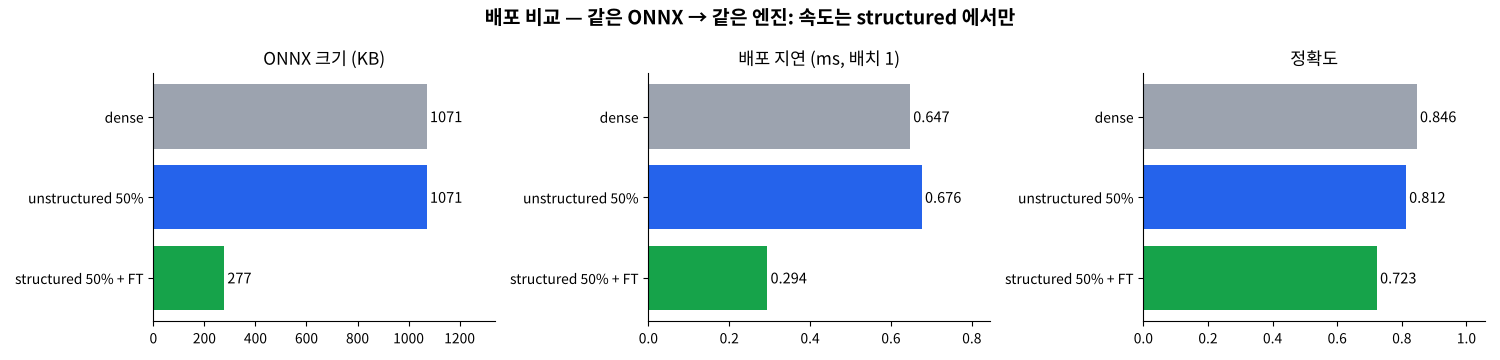

In [ ]:
#@title 🖼 그림 — 배포 비교 — dense · unstructured 50% · structured 50% 를 같은 엔진으로
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day5/img/f7_deploy.png", embed=True, width=860))

In [ ]:
# ▶ 배포 지연 측정 도구 — Day 4 deploy_lat 의 FP16 판
def deploy_lat(onnx_path, n=300):
    if TRT_OK:
        f = TRTInfer(build_once(onnx_path, onnx_path.replace(".onnx", "_fp16.engine"), fp16=True))
    else:
        s = make_session(onnx_path); f = lambda x, s=s: s.run(None, {"input": x})[0]
    return bench_fn(lambda: f(X_ev[:1]), n=n, warm=30)["mean"]

def onnx_conv_stats(path):
    # ONNX 안 Conv weight 들의 원소 수 · 0 비율
    g = onnx.load(path).graph; init = {i.name: numpy_helper.to_array(i) for i in g.initializer}
    ws = [init[n.input[1]] for n in g.node if n.op_type == "Conv" and n.input[1] in init]
    total = sum(w.size for w in ws)
    return {"conv_params": int(total), "zero_frac": float(sum((w == 0).sum() for w in ws) / total)}
print("측정:", BACKEND)

**✍️ 직접 구현 7-1** 세 모델을 배치 1 ONNX 로 내보내세요: `rn20_dense.onnx` (rn20), `rn20_us50.onnx` (`prune_unstructured(rn20, 0.5)`), `rn20_p50.onnx` (`torch.load("rn20_p50_ft.pth", weights_only=False)`). 각 ONNX 의 크기 (KB) · `onnx_conv_stats` · ORT 정확도 (`onnx_acc`) 를 `onnx_df` (열 `model, size_kb, conv_params, zero_frac, acc`) 로 만드세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 7-1 — 실행할 때마다 하나씩
show_hint("7-1", "c3RydWN0dXJlZCDrqqjrjbg6IGB0b3JjaC5sb2FkKCJybjIwX3A1MF9mdC5wdGgiLCB3ZWlnaHRzX29ubHk9RmFsc2UpYC4e66qo642466eI64ukIGBwID0gZXhwb3J0X2IxKG0sIOqyveuhnClgIOKGkiBgeyJtb2RlbCI6IG5hbWUsICJzaXplX2tiIjogc2l6ZV9rYihwKSwgKipvbm54X2NvbnZfc3RhdHMocCksICJhY2MiOiBvbm54X2FjYyhwKX1gLg==")

In [ ]:
# ✍️ 직접 구현 7-1 — 세 모델을 ONNX 로
models = {}   # TODO: "dense", "unstructured 50%", "structured 50% + FT"
paths = {"dense": "rn20_dense.onnx", "unstructured 50%": "rn20_us50.onnx", "structured 50% + FT": "rn20_p50.onnx"}
rows = []
# TODO
onnx_df = pd.DataFrame(rows)
display(onnx_df.round(4))

In [ ]:
d_ = onnx_df.set_index("model")
assert abs(d_.size_kb["dense"] - d_.size_kb["unstructured 50%"]) < 5 and d_.conv_params["dense"] == d_.conv_params["unstructured 50%"]
assert d_.zero_frac["unstructured 50%"] > 0.45 and d_.conv_params["structured 50% + FT"] < 0.3 * d_.conv_params["dense"]
assert abs(d_.acc["dense"] - FP32_ACC) < 0.003 and d_.size_kb["structured 50% + FT"] < 0.35 * d_.size_kb["dense"]
print(f"✅ ONNX 크기 — dense {d_.size_kb['dense']:.0f} · unstructured {d_.size_kb['unstructured 50%']:.0f} · structured {d_.size_kb['structured 50% + FT']:.0f} KB")

In [ ]:
#@title 🔒 정답 보기 7-1 — 강사가 알려 준 실습 7-1 잠금 코드를 입력하세요
show_answer("7-1", (
    "OVJjuJBUHV3W2B6lp+z8ZmVx26uCaTbhmpq4ZWAM/zKuleY47MH2vG7bnshU3twt1tweJisOm8zU0uL9+OODm/5A"
    "GEJYzL2MVEG60YY8Ap3Z4qRGGbfgNRifolXr0tV1c2qMB7aq3JeckRUvvfWpnXxtFQuERJy5bD4Zr3f6JnTvfm4C"
    "koAUtdeD6fM9r4d6vA47Q1RDTrysXiOC+zOI4yA+787szhHRNIAUB3WR+XWOa5qV/k+CDnzNJCHVugS/NUPEu2aV"
    "8ccDMk0al6OLe9QHurZ9mHXK0QmBAaSz/Vm1+RAYNaT3cUuXxy8XMLFEfrw4DCNlvBjbFXyOh7mWmJQ2BQnLdCSL"
    "UCb49Pau6aysh8io8U1OqAqDgXk6LcpWp2sBvNpQxOn7yCb2uNgIJuUPOh7xlzE7Iw5OtEqX3D9dH9zUaVSugbpb"
    "zjhiF/j0ELrnCRVzEHWx/oyJnjMzaDiZ/qWKxwKPCKv/IFbmYzmb4hp4pxrTG4RpAezTyx/sJuJvcejnGFQoB9aE"
    "+a7miEr3NrH8GwZnvVfNC4D3zWu+qzgb+BoliWe002ligPNu9pLUJOuGxo616w05KDFpNCJso4y5xCPPLUioKpfK"
    "ofVtYh75OOiQ/A4U+tKO7lK78gChFE0CZwKnaflA6eUPpjcok2KAAnjjxEpXTdya0OkO3FlNfNg/bGDkTicaGHzU"
    "w8rTqWDF6zshSelH2icWTqas8YlQ8S172yTtdWCIxhJ8Y9OO+eiEDFir0oNfu8RjAXWFQVzFXmS9l0G3im0glQAp"
    "gF+5U8sJvLaV0xqhLx/m3NZHAhPfDcmKTR4Js+kqtYLBhszdqa+mMPIFmNUCVo9wGh3QtL7Px69deGSXu90a9os2"
    "N/azjt9K7EyzWR6WQGaomQHp8i5lt211j2xT0wGdxA/SNvkq3/lTdE2ochL6kDipwG7OgkAUXRAjDaXBIiUFnJG7"
    "+Jm8pT06id8iduPxYm6W7XBboS3B3wUesPeVeD8dDii5/5EnljXiOVhX8YmFXdql4XYJtOFa0PGXeJKLW97ZzDdn"
    "3LmK+lw77hFSGk5XWYaVrlKh4GqAPPy6skJk1ob3Uwq6y+oQkX+9+iU75ETkVrGJf1h1f8LU/y7gZT1ufEG05Lde"
    "Gz96dQt3b0CqmVteRGN4M2fZ0AcExA=="
))


**✍️ 직접 구현 7-2** `deploy_lat` 로 세 ONNX 의 지연을 재서 `deploy_df` (열 `model, acc, latency_ms, speedup`, speedup = dense 지연 / 그 모델 지연) 를 만드세요. 그리고 `qp_baseline.csv` 에 **3행** (`day="Day5"`, `model` = `rn20_dense` · `rn20_us50` · `rn20_p50`, `quant="FP32 (<model 이름>)"`, `size_kb`, `acc`, `mean_ms`, 나머지 `p95_ms · fps_b32` 는 NaN) 을 추가하세요. 파일이 없으면 새로 만들고, 같은 (day, model) 은 마지막 것만 남깁니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 7-2 — 실행할 때마다 하나씩
show_hint("7-2", "YGRlcGxveV9kZiA9IG9ubnhfZGZbWyJtb2RlbCIsICJhY2MiXV0uY29weSgpYCDihpIgYGRlcGxveV9kZlsibGF0ZW5jeV9tcyJdID0gW2RlcGxveV9sYXQocGF0aHNbbV0pIGZvciBtIGluIGRlcGxveV9kZi5tb2RlbF1gLh5zcGVlZHVwID0gYGRlcGxveV9kZi5sYXRlbmN5X21zWzBdIC8gZGVwbG95X2RmLmxhdGVuY3lfbXNgLh5jc3Y6IERheSA0IDgtNCDsmYAg6rCZ7J2AIOuwqeyLnSDigJQgYHBkLmNvbmNhdChbLi4uXSkuZHJvcF9kdXBsaWNhdGVzKHN1YnNldD1bImRheSIsICJtb2RlbCJdLCBrZWVwPSJsYXN0IilgLg==")

In [ ]:
# ✍️ 직접 구현 7-2 — 엔진 지연 비교 · qp_baseline
deploy_df = None   # TODO: 열 model, acc, latency_ms, speedup
display(deploy_df.round(3))

tags = {"dense": "rn20_dense", "unstructured 50%": "rn20_us50", "structured 50% + FT": "rn20_p50"}
# TODO: qp_baseline.csv 에 Day5 3행 추가

In [ ]:
s_ = deploy_df.set_index("model").speedup
assert 0.75 < s_["unstructured 50%"] < 1.3 and s_["structured 50% + FT"] > 1.15
b_ = pd.read_csv("qp_baseline.csv"); assert set(b_[b_.day == "Day5"].model) >= {"rn20_dense", "rn20_us50", "rn20_p50"}
print(f"✅ {BACKEND} — unstructured {s_['unstructured 50%']:.2f}배 · structured {s_['structured 50% + FT']:.2f}배 — 속도는 structured 에서만")

In [ ]:
#@title 🔒 정답 보기 7-2 — 강사가 알려 준 실습 7-2 잠금 코드를 입력하세요
show_answer("7-2", (
    "8OyqZI6PZid/YIPEO8XLEdVSdcsROlBS+yx9JClz1My/zfGRCtf+fny/xD7XkjFm8NOV3s97bekh7q6kRYHGgXvn"
    "eS+Ez0Hn16FOs4KrVOia5MdTrUAthvRwROoBfwLabvDcRbfpxRMJ1Do/OzLD2DH/TdUYGFWVL+Dl7Gfj7QRC38Ct"
    "maQZg6S9/73TcOWkeC3icLmh8a6UJoxu1WNVDZt6eNjyJHxVnpMlibeV/7e0rB9fXWdYgsUAi3AJ8+DcGxGwVqEc"
    "mO7ZfwP3Eqb2UJQVJVLafWPujPl4p8R098LMAz85Dh0oWrw2GOB06l7vlU6N0aq82nWETBEyIx7nXDmhRrRSD0Lr"
    "VP8hRagdU3HjHnCcXM70LWMHvuxwlsDaL5NjAMroEj9Mz1vq1heMUWqZoSBth5odGJuGorvbcXJzHnItReXESE4C"
    "iESGVREosgaC7HZkV0l0o62y8Nxo1QElTBOXbL+3VWajx27JtfNqQVCswhWN0fFH32stJycw7Mwf6sppmEeD/PAW"
    "70GwNSms5GniEfJKOjOUSoOs2QWBEci2NuHFz0IQcSUoh4Q75XmEc4RJnEIupOlfVNli29+qru47h5AHVvX9LY7X"
    "O3HZ/ZqvYGyTBYjLr7YhegUf5U5iNNPb3AJpoJjESo4XBxF+L9MKcQjW+MFxsjC/q7Y0xVSA84ionSLL9jy7KiPF"
    "FdrAeGMiWvSdC2QLib0JryyrugEO6rbgn+EKJsphks08iOZDJ1C+A/JZqXBJIsLom0t/jQAdXF9RfxV8nM9cxz3R"
    "6hIRKve4CuRPnou1J4fsPVQgDMG5uhrt5oXSbjVne1GJBlvvNnHs26aPj/35Cp5JoJlsuPK3QMA9hXpHNc7JDd21"
    "lIUj4/bySg4iCxw5ckjAnCDiKVhFH/sFVXUbU4XjX9gydSfSBoSAKthXbEijvxa1EE4Y6OITcbbenvo03nfDbRXG"
    "H90huGxoYQOmiYFb845bg054ZC4kBBf3L3xwFpJvjTScHjdQd62OQGzpHKcTJACSb7sbEEOeXMMOsihX1dgV7TD0"
    "otKDUmK1KBBQHMSdGnrf6/d6XMBsWuPT9eZqYb7TRoRS85mpOBCX58vnIe/ksoXSDeGHxZ8/p77pLuGACrUeLP3P"
    "ZBBvHyEYZ8H7AyJHkH47I50SQdLSAO4U2mD1+Yum4/Sgk80WxMe6xTCz9WfMl8Ho1FsIaeGBkZvo49BOEN2TEYRZ"
    "dEGCbJqn/VbmYiUCSQyV5vdTUVadHlgsIg7y2udtcBJTI7vUGl3+jbcAIzJFqjVTZQKEXwEL7iDjvgjwzRQYPiqX"
    "tB3ie+IAJzFR6nSb4vtbX3HlRRL5ExuRCg1tNU1K48ZMbCySkww1OYLMF99YqoRib82CMWJ0aE9qPCmr93/AznK5"
    "l2cOyfFbyi5zJHzflwsuEjkbHdMbA3nbOnRY0/9tCSOpD2RWO7kGlDp0GVlmpElT4gxfYQ7XhVeFh7QC9LoKUGOH"
    "HGXXAzvDM2tuELtxfzw4GEoEP18EpNgI8+HZMjKLlVKU77gysHqDO6FAicub350ar/Hl8q/SDW/ZY8qjQ+aFD0XF"
    "OXRS0UraV+OztjEqusAY9h8WXlaID2pGLRvoMAE35x1EFnOvEawKWFKn3yQEtqi1zrBjL7/06Lsv9Jmasn9wk9me"
    "U1NjT/MNelVYLaKRzT5BsaQmnRxtfDqC+AdQXiq73y45pFz3nUeH+YTla1E5mkT56XPNfQjs3hWqzni/6lVy6It1"
    "owRNieJ/A42E5BXn9n0UHcT7B3mFT+74fJZsvXeo6mVp0xsQS/O8nLar2cA9sQTIKY6LkmMpoHxd+pQmCLhH23Mf"
    "prQxkd8WF0BMjubTdFD/3LdYD5qB101fStwYK/2DXrk1zm21lYCL40b3QLLOrw1GcnT4fuoRGuayx+lNYgg34R7W"
))


#### 📌 7교시 정리

- unstructured 50%: ONNX 크기 · Conv 모양 · 엔진 속도 모두 dense 와 같다.
- structured 50%: Conv 가 진짜로 작아져 크기 1/4, 엔진에서도 빨라진다 — 단 MACs 비율만큼은 아니다.
- **실무에서 속도를 얻는 것은 structured pruning.** 결과는 `qp_baseline.csv` 에 모은다.

## 8교시 — 미니 프로젝트: 가지치기 비율 곡선

**질문** — "ResNet-20 을 얼마나 잘라도 될까?" 를 **곡선**으로 답합니다.

1. structured 비율 **0 / 20 / 40 / 60%** 각각 → `prune_channels` → **같은 fine-tuning (lr 1e-2 · 3 epoch)** → MACs · params · 정확도 · 배포 지연.
2. **MACs – 정확도**, **지연 – 정확도** 곡선을 그립니다.
3. **선택 기준**: 정확도가 **FP32 (0.846) 대비 3%p 이내** 인 가장 큰 비율.

> 기준을 '1%p 이내' 가 아니라 '3%p 이내' 로 둔 이유 — 오늘의 fine-tuning 은 학습용 10,000장 · 3 epoch 라는 **짧은 예산**이라, 비율 0 (자르지 않고 fine-tuning 만) 도 0.84 안팎입니다. 실무에서는 전체 50,000장으로 수십 epoch 학습한 뒤 1%p 기준을 씁니다.

예상 시간: GPU 1 ~ 2분, CPU 약 4분 (fine-tuning 4번).

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | 비율 4개 × (prune → fine-tuning → 측정) 표 `sweep_df` | 20 |
| 2 | MACs – 정확도 · 지연 – 정확도 그림 `prune_curve.png` | 20 |
| 3 | 기준 (FP32 대비 3%p 이내) 으로 `best_ratio` 고르기 | 20 |
| 4 | `pruning_sweep.csv` · `rn20_pruned_best.onnx` · `qp_baseline.csv` 저장 | 20 |
| 5 | 고른 모델의 이득 요약 `summary` | 10 |
| 6 | 결론 쓰기 (마크다운) | 10 |

> 미니 프로젝트에는 **정답 보기 셀이 없습니다.** 채점 셀을 실행하면 자동 채점 점수와 **정답 열람 기록**이 나옵니다 (과제 6 은 강사 채점).

> 🎬 **애니메이션** [D5-8 pruning 비율 탐색](https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/animation.html#d5-8)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

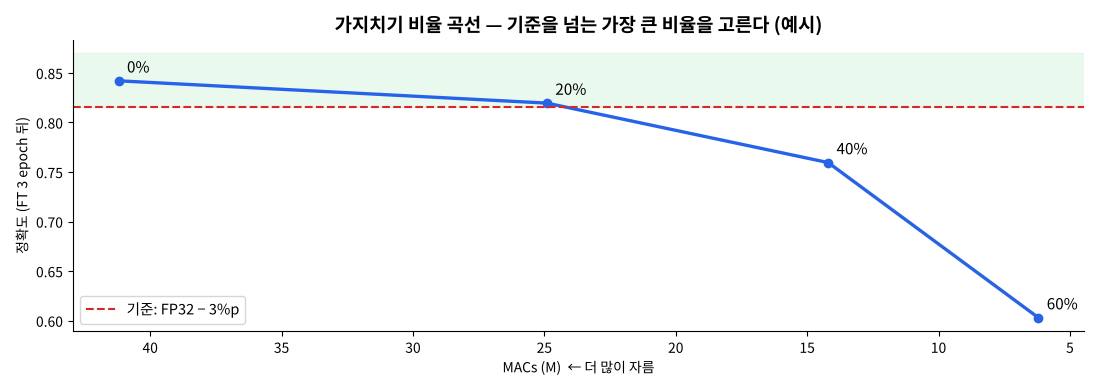

In [ ]:
#@title 🖼 그림 — 가지치기 비율 곡선 — MACs · 지연이 줄수록 정확도는 어디서 꺾이나
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day5/img/f8_sweep.png", embed=True, width=860))

**과제 1 (20점)** `RATIOS = [0.0, 0.2, 0.4, 0.6]` 각각에 대해 (ratio 0 은 `rn20` 복사본) `prune_channels` → MACs · params 측정 (fine-tuning **전**, CPU) → `acc_before` → `finetune` (3 epoch) → `acc` → `rn20_s{비율%}.onnx` 로 내보내 `deploy_lat`. 결과를 `sweep_df` (열 `ratio, macs_m, params, acc_before, acc, latency_ms, ft_s`) 로, 모델은 `sweep_models[ratio]` 에 담으세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 8-1 — 실행할 때마다 하나씩
show_hint("8-1", "cmF0aW8gMCDsnYAgYGNvcHkuZGVlcGNvcHkocm4yMClgLCDrgpjrqLjsp4DripQgYHBydW5lX2NoYW5uZWxzKHJuMjAsIHIpYC4e7Iic7IScOiBjb3VudF9vcHNfYW5kX3BhcmFtcyAoQ1BVKSDihpIgYWNjX2JlZm9yZSDihpIgYHQgPSBmaW5ldHVuZShtKWAg4oaSIGFjYyDihpIgYGV4cG9ydF9iMShtLCBmInJuMjBfc3tpbnQociAqIDEwMCl9Lm9ubngiKWAg4oaSIGBkZXBsb3lfbGF0YC4=")

In [ ]:
# ✍️ 과제 1 — 비율 4개 × (prune → fine-tuning → 측정)
RATIOS = [0.0, 0.2, 0.4, 0.6]
rows, sweep_models = [], {}
# TODO
sweep_df = pd.DataFrame(rows)
display(sweep_df.round(4))

**과제 2 (20점)** 두 칸짜리 그림을 그려 `prune_curve.png` 로 저장하세요: 왼쪽 **x = MACs (M), y = 정확도**, 오른쪽 **x = 지연 (ms), y = 정확도**. 점마다 비율을 글자로 표시하고, 두 칸 모두 **FP32 − 3%p 기준선** (점선) 을 그리세요 (제목 · 축 이름 포함).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-2 — 실행할 때마다 하나씩
show_hint("8-2", "YGZpZ18sIGF4cyA9IHBsdC5zdWJwbG90cygxLCAyLCBmaWdzaXplPSgxMCwgMy42KSlgLh7soJDrp4jri6Qg6riA7J6QOiBgYXguYW5ub3RhdGUoZiJ7aW50KHIucmF0aW8gKiAxMDApfSUiLCAoeCwgeSksIHRleHRjb29yZHM9Im9mZnNldCBwb2ludHMiLCB4eXRleHQ9KDUsIDUpKWAuHuq4sOykgOyEoDogYGF4LmF4aGxpbmUoRlAzMl9BQ0MgLSAwLjAzLCBscz0iLS0iKWAgwrcg7KCA7J6lIGBmaWdfLnNhdmVmaWcoInBydW5lX2N1cnZlLnBuZyIsIGRwaT0xMjApYC4=")

In [ ]:
# ✍️ 과제 2 — 곡선 그림
# TODO: 왼쪽 MACs–정확도, 오른쪽 지연–정확도, 기준선, 저장 prune_curve.png

**과제 3 (20점)** 정확도가 `FP32_ACC - 0.03` 이상인 비율 중 **가장 큰 것** 을 `best_ratio` 로 고르세요 (없으면 0.0). 고른 행을 `best_row` (sweep_df 의 한 행, Series) 로 두세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 8-3 — 실행할 때마다 하나씩
show_hint("8-3", "YG9rXyA9IHN3ZWVwX2RmW3N3ZWVwX2RmLmFjYyA+PSBGUDMyX0FDQyAtIDAuMDNdYC4eYGJlc3RfcmF0aW8gPSBmbG9hdChva18ucmF0aW8ubWF4KCkpIGlmIGxlbihva18pIGVsc2UgMC4wYCwgYGJlc3Rfcm93ID0gc3dlZXBfZGYuc2V0X2luZGV4KCJyYXRpbyIpLmxvY1tiZXN0X3JhdGlvXWAu")

In [ ]:
# ✍️ 과제 3 — 비율 고르기
best_ratio = None   # TODO
best_row = None     # TODO
print(f"기준 {FP32_ACC - 0.03:.4f} 이상 → best_ratio {best_ratio} | MACs {best_row.macs_m:.1f}M · 정확도 {best_row.acc:.4f} · 지연 {best_row.latency_ms:.3f} ms")

**과제 4 (20점)** (1) `sweep_df` 를 `pruning_sweep.csv` 로 저장하세요. (2) `sweep_models[best_ratio]` 를 `rn20_pruned_best.onnx` 로 내보내세요. (3) `qp_baseline.csv` 에 1행 (`day="Day5"`, `model="rn20_pruned_best"`, `quant=f"FP32 (structured {비율%}% + FT)"`, `size_kb`, `acc`, `mean_ms` = best_row 의 지연, 나머지 NaN) 을 7-2 와 같은 방식으로 추가하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 8-4 — 실행할 때마다 하나씩
show_hint("8-4", "YHN3ZWVwX2RmLnRvX2NzdigicHJ1bmluZ19zd2VlcC5jc3YiLCBpbmRleD1GYWxzZSlgIMK3IGBleHBvcnRfYjEoc3dlZXBfbW9kZWxzW2Jlc3RfcmF0aW9dLCAicm4yMF9wcnVuZWRfYmVzdC5vbm54IilgLh5xcF9iYXNlbGluZSDsnYAgNy0yIOyZgCDqsJnsnYAg67Cp7Iud7Jy866GcIDHtloku")

In [ ]:
# ✍️ 과제 4 — 저장
# TODO: pruning_sweep.csv · rn20_pruned_best.onnx · qp_baseline.csv (Day5, rn20_pruned_best)

**과제 5 (10점)** 고른 모델의 이득을 비율 0 (fine-tuning 한 dense) 대비로 요약한 `summary` 를 만드세요: `{"best_ratio": ..., "macs_x": MACs 감소 배수, "params_x": params 감소 배수, "speedup": 지연 속도비, "acc_drop_pp": FP32_ACC 대비 정확도 하락 (%p)}`.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 8-5 — 실행할 때마다 하나씩
show_hint("8-5", "6riw7KSAIO2WiTogYGIwID0gc3dlZXBfZGYuc2V0X2luZGV4KCJyYXRpbyIpLmxvY1swLjBdYC4e67Cw7IiY64qUICfquLDspIAgLyDqs6Drpbgg66qo6424Jywg7ZWY65297J2AIGAoRlAzMl9BQ0MgLSBiZXN0X3Jvdy5hY2MpICogMTAwYC4=")

In [ ]:
# ✍️ 과제 5 — 이득 요약
summary = {}   # TODO: best_ratio, macs_x, params_x, speedup, acc_drop_pp
print({k: round(float(v), 3) for k, v in summary.items()})

### 과제 6 — 결론: 얼마나, 어떻게 자를까 (10점)

아래 셀에 답을 쓰세요 (각 2~3줄).

1. 오늘 곡선에서 고른 비율과 그 근거를 숫자 (MACs · 지연 · 정확도) 로. 기준을 '1%p 이내' 로 바꾸면 어떻게 될까요? 무엇을 바꾸면 1%p 안에 들 수 있을까요?
2. unstructured 70% 와 structured 20% 중 **T4 에서 배포할 모델** 로 무엇을 고르겠습니까? 이유는?
3. 고른 모델이 MACs 는 줄었는데 지연은 (ORT CPU 에서) 오히려 늘었다면 — 왜 그럴까요? 어떻게 확인하고 고칠 수 있을까요? (힌트: 각 층의 채널 수)
4. 오늘의 가지치기 모델에 Day 2 ~ 4 의 INT8 양자화를 더하면 어떤 순서로 하겠습니까? (prune → FT → PTQ/QAT ?)

✍️ *여기에 답을 쓰세요.*

### 채점 셀

In [ ]:
score = 0
try:
    assert sweep_df.ratio.tolist() == [0.0, 0.2, 0.4, 0.6] and list(sweep_df.columns) == ["ratio", "macs_m", "params", "acc_before", "acc", "latency_ms", "ft_s"]
    assert sweep_df.macs_m.is_monotonic_decreasing and (sweep_df.acc > sweep_df.acc_before - 0.01).all() and sweep_df.acc[0] > 0.8 and sweep_df.acc[1] > 0.7
    assert set(sweep_models) == set(RATIOS) and (sweep_df.ft_s > 0).all()
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", repr(e))
try:
    assert os.path.getsize("prune_curve.png") > 10000
    score += 20; print("✅ 과제 2  +20")
except Exception as e: print("❌ 과제 2", repr(e))
try:
    ok_ = sweep_df[sweep_df.acc >= FP32_ACC - 0.03]
    assert best_ratio == (float(ok_.ratio.max()) if len(ok_) else 0.0) and abs(best_row.acc - sweep_df.set_index("ratio").acc[best_ratio]) < 1e-9
    score += 20; print("✅ 과제 3  +20")
except Exception as e: print("❌ 과제 3", repr(e))
try:
    c_ = pd.read_csv("pruning_sweep.csv"); b_ = pd.read_csv("qp_baseline.csv")
    assert len(c_) == 4 and "rn20_pruned_best" in set(b_[b_.day == "Day5"].model)
    _o = make_session("rn20_pruned_best.onnx").run(None, {"input": X_ev[:1]})[0]
    assert _o.shape == (1, 10) and onnx_conv_stats("rn20_pruned_best.onnx")["conv_params"] == sum(m.weight.numel() for m in sweep_models[best_ratio].modules() if isinstance(m, nn.Conv2d))
    score += 20; print("✅ 과제 4  +20")
except Exception as e: print("❌ 과제 4", repr(e))
try:
    b0_ = sweep_df.set_index("ratio").loc[0.0]
    assert summary["best_ratio"] == best_ratio and abs(summary["macs_x"] - b0_.macs_m / best_row.macs_m) < 1e-6
    assert abs(summary["speedup"] - b0_.latency_ms / best_row.latency_ms) < 1e-6 and abs(summary["acc_drop_pp"] - (FP32_ACC - best_row.acc) * 100) < 1e-6
    score += 10; print("✅ 과제 5  +10")
except Exception as e: print("❌ 과제 5", repr(e))
print(f"\n자동 채점 {score} / 90  (+ 과제 6 강사 채점 10점) | 장치: {DEV} · 측정: {BACKEND}")
seen = [l.split("\t")[0] for l in open(".qp_answer_log")] if os.path.exists(".qp_answer_log") else []
seen = list(dict.fromkeys(seen))
print(f"정답 열람 {len(seen)}개" + (f" — {', '.join(seen)}" if seen else " — 없음 👍"))

#### 📌 8교시 정리

- 비율 하나가 아니라 **곡선** (MACs – 정확도 – 지연) 을 그려 '무릎' 을 찾는다.
- 비교의 공정성: 비율 0 도 같은 fine-tuning, 같은 평가 데이터, 같은 엔진.
- 기준 (몇 %p 이내) 과 학습 예산이 결론을 바꾼다 — 둘 다 결과와 함께 적는다.

## 오늘의 정리

### 셀프 체크

- [ ] magnitude 기준 · 가지치기 단위 (weight · N:M · filter · layer) 를 설명하고 weight 분포에서 mask 를 만들었다
- [ ] `torch.nn.utils.prune` 의 weight_orig · weight_mask · `prune.remove` 를 설명하고 layer 별 · global 을 비교했다
- [ ] 0 이 90% 인 모델의 저장 · 압축 크기와 지연을 재고, 2:4 sparsity 의 조건 (Ampere+) 을 말할 수 있다
- [ ] conv1 → bn1 → conv2 를 손으로 줄이고, residual 이 왜 제약인지 오류로 확인했다
- [ ] DependencyGraph · MetaPruner 로 ResNet-20 을 줄이고 MACs · params 를 셌다
- [ ] fine-tuning 회복 곡선을 그리고 one-shot vs iterative 를 같은 예산으로 비교했다
- [ ] ONNX → 엔진에서 unstructured · structured 의 속도를 비교하고 qp_baseline.csv 에 기록했다

### 다음 시간 (Day 6) 예고

오늘의 50% 모델은 정확도 0.72 로 FP32 와 12%p 차이가 남았습니다. 월요일에는 원본 ResNet-20 을 **선생님**, 오늘의 `rn20_p50_ft.pth` 를 **학생**으로 두고 **지식 증류 (Knowledge Distillation)** 로 이 차이를 줄입니다. 그리고 Day 1 ~ 6 의 양자화 · 가지치기 · KD 를 묶어 **prune → KD → INT8** 최종 파이프라인과 `qp_baseline.csv` 전체 비교로 과정을 마무리합니다.

> 📦 `rn20_p50_ft.pth` · `qp_baseline.csv` 를 내 컴퓨터 (또는 Drive) 에 내려받아 두세요. 내일 노트북은 없으면 강의 자료 서버에서 같은 모델을 내려받습니다.

## 📝 Day 5 복습 퀴즈 — 수업이 끝난 뒤

오늘 배운 1~8교시 내용을 **24문항**으로 점검합니다. 9가지 유형이 섞여 있습니다.

👉 **[Day 5 복습 퀴즈 열기](https://imguru-mooc.github.io/AI_CAMPUS/QP-day5/review_quiz.html)**

1. 이름을 입력하고 24문항을 모두 풉니다.
2. **채점하기** → 정오와 해설이 나타납니다. 채점 후에는 답이 잠깁니다.
3. **제출 (오답 정리)** → 점수 · 결과 코드 · 오답 정리를 **텍스트 복사** 또는 캡처로 강사가 안내한 곳에 제출합니다.